In [1]:
# To generate XRD patterns, and TM-O bond length distribution information.

In [1]:
import json
from pathlib import Path
from pymatgen.analysis.diffraction.xrd import XRDCalculator

In [2]:
doubleTM_elec0 = json.load(open(Path('..') / 'data' / 'doubleTM_structures_elec0.json'))
doubleTM_elec1 = json.load(open(Path('..') / 'data' / 'doubleTM_structures_elec1.json'))
singleTM = json.load(open(Path('..') / 'data' / 'singleTM_structures.json'))

all_structures = doubleTM_elec0 | doubleTM_elec1 | singleTM

with open("../data/structures.json", "w") as file:
    json.dump(all_structures, file)

In [23]:
import re
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Simple hull extraction for doubleTM / singleTM DFT summaries
# - same lower-hull idea used in dft_oxi_state.ipynb
# - outputs long-format CSV for easy filtering/splitting
# ------------------------------------------------------------

double_csv = Path('../data/doubleTM_dft_tighter.csv')
single_csv = Path('../data/singleTM_tighter_conv.csv')
out_double = Path('../data/doubleTM_hull_points.csv')
out_single = Path('../data/singleTM_hull_points.csv')


def apply_basic_quality_filter(df: pd.DataFrame) -> pd.DataFrame:
    """
    Keep rows that are usable for hull construction.
    Criteria:
      - status == 'OK' (if status column exists)
      - converged == True (if converged column exists, case-insensitive)
      - n_custodian_errors == 0 (if n_custodian_errors column exists)
    """
    mask = pd.Series(True, index=df.index)

    if 'status' in df.columns:
        mask &= df['status'].astype(str).eq('OK')

    if 'converged' in df.columns:
        c = df['converged']
        if c.dtype == object:
            c = c.astype(str).str.lower().eq('true')
        mask &= c

    if 'n_custodian_errors' in df.columns:
        nerr = pd.to_numeric(df['n_custodian_errors'], errors='coerce').fillna(0)
        mask &= nerr.eq(0)

    return df[mask].copy()


def expand_parentheses(formula: str) -> str:
    """
    Convert formulas like Na2(FeMn)2O4 into Na2Fe2Mn2O4 by expanding parentheses.
    """
    text = str(formula)
    group_pat = re.compile(r'\(([^()]+)\)(\d*)')
    atom_pat = re.compile(r'([A-Z][a-z]?)(\d*)')

    while True:
        m = group_pat.search(text)
        if m is None:
            break
        inner = m.group(1)
        mult = int(m.group(2) or '1')

        expanded = []
        for el, n in atom_pat.findall(inner):
            cnt = int(n or '1') * mult
            expanded.append(f"{el}{cnt if cnt != 1 else ''}")

        text = text[:m.start()] + ''.join(expanded) + text[m.end():]

    return text


def parse_formula_counts(formula):
    """
    Convert formulas like Na2Fe2Mn2O4 into {'Na': 2, 'Fe': 2, 'Mn': 2, 'O': 4}.
    """
    if pd.isna(formula):
        return None
    text = str(formula).replace(' ', '')
    if not text:
        return None

    text = expand_parentheses(text)
    tokens = re.findall(r'([A-Z][a-z]?)(\d*)', text)
    if not tokens:
        return None

    counts = {}
    for el, n in tokens:
        counts[el] = counts.get(el, 0) + int(n or '1')
    return counts


def lower_hull_indices(xs, ys):
    """Return indices on the lower convex hull (2D monotone-chain)."""
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    if xs.size == 0:
        return []

    # Keep only one lowest-energy point for each x.
    keep = []
    for x in np.sort(np.unique(xs)):
        idx = np.where(np.isclose(xs, x))[0]
        keep.append(idx[np.argmin(ys[idx])])

    if len(keep) <= 2:
        return sorted(keep, key=lambda i: xs[i])

    # Monotone Chain Convex Hull a.k.a. Andrew's algorithm
    ordered = sorted(keep, key=lambda i: (xs[i], ys[i]))
    hull = []
    for k in ordered:
        while len(hull) >= 2:
            i, j = hull[-2], hull[-1]
            cross = (xs[j] - xs[i]) * (ys[k] - ys[i]) - (ys[j] - ys[i]) * (xs[k] - xs[i])
            if cross <= 0:
                hull.pop()
            else:
                break
        hull.append(k)
    return hull


def add_xna_and_etmo2(df: pd.DataFrame, tm_mode: str) -> pd.DataFrame:
    """
    tm_mode:
      - 'double' -> tm_pair column (e.g. Co_Ni)
      - 'single' -> tm column (e.g. Co)
    """
    df = df.copy()
    for col in ['natoms', 'energy_eV', 'energy_per_atom_eV']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df['formula_counts'] = df['formula'].apply(parse_formula_counts)

    def tm_list_from_row(row):
        if tm_mode == 'double':
            val = str(row.get('tm_pair', ''))
            if '_' not in val:
                return []
            return val.split('_')
        val = str(row.get('tm', ''))
        return [val] if val else []

    def xna_from_row(row):
        counts = row['formula_counts']
        if not isinstance(counts, dict):
            return np.nan
        tms = tm_list_from_row(row)
        if not tms:
            return np.nan
        n_tm = sum(counts.get(t, 0) for t in tms)
        if n_tm <= 0:
            return np.nan
        return counts.get('Na', 0) / n_tm

    def energy_per_tmo2(row):
        counts = row['formula_counts']
        if not isinstance(counts, dict):
            return np.nan

        tms = tm_list_from_row(row)
        if not tms:
            return np.nan

        n_formula = sum(counts.values())
        natoms = row.get('natoms', np.nan)
        if not np.isfinite(natoms) or natoms <= 0 or n_formula <= 0:
            return np.nan

        n_tm_formula = sum(counts.get(t, 0) for t in tms)
        if n_tm_formula <= 0:
            return np.nan

        # number of TMO2 units in this supercell
        scale = natoms / n_formula
        n_tmo2 = n_tm_formula * scale
        if n_tmo2 <= 0:
            return np.nan

        e_tot = row.get('energy_eV', np.nan)
        if np.isfinite(e_tot):
            e_total = float(e_tot)
        else:
            epa = row.get('energy_per_atom_eV', np.nan)
            if not np.isfinite(epa):
                return np.nan
            e_total = float(epa) * float(natoms)

        return e_total / n_tmo2

    df['xNa'] = df.apply(xna_from_row, axis=1)
    df['E_TMO2_eV'] = df.apply(energy_per_tmo2, axis=1)
    return df.dropna(subset=['xNa', 'E_TMO2_eV']).copy()


def build_hull_table(df_points: pd.DataFrame, id_col: str, include_elec: bool) -> pd.DataFrame:
    rows = []
    for sid in sorted(df_points[id_col].dropna().unique()):
        sub = df_points[df_points[id_col] == sid].copy().reset_index(drop=True)
        if len(sub) < 2:
            continue

        hidx = lower_hull_indices(sub['xNa'].to_numpy(), sub['E_TMO2_eV'].to_numpy())
        if len(hidx) < 2:
            continue

        stable = sub.iloc[hidx].sort_values('xNa').reset_index(drop=True)
        stable['hull_order'] = np.arange(len(stable))
        rows.append(stable)

        # quick printout so orderings are visible in the notebook output
        show_cols = [id_col, 'hull_order', 'xNa', 'phase', 'ordering']
        if include_elec:
            show_cols.append('elec')
        print(f"\n=== {sid}: hull points ===")
        print(stable[show_cols].to_string(index=False))

    if not rows:
        return pd.DataFrame()

    out = pd.concat(rows, ignore_index=True)
    if include_elec:
        cols = [id_col, 'hull_order', 'phase', 'ordering', 'elec', 'xNa', 'E_TMO2_eV', 'formula']
    else:
        cols = [id_col, 'hull_order', 'phase', 'ordering', 'xNa', 'E_TMO2_eV', 'formula']
    return out[cols].sort_values([id_col, 'hull_order']).reset_index(drop=True)


# ----------------------------
# 1) doubleTM hull CSV
# ----------------------------
df_d = pd.read_csv(double_csv)
df_d = apply_basic_quality_filter(df_d)
df_d = add_xna_and_etmo2(df_d, tm_mode='double')
df_d['elec'] = df_d['elec'].fillna('elec_unknown').astype(str)

# One representative point per (tm_pair, phase, ordering, elec, xNa)
# using minimum E_TMO2_eV for robustness.
pts_d = (
    df_d.groupby(['tm_pair', 'phase', 'ordering', 'elec', 'xNa'], as_index=False)
        .agg(E_TMO2_eV=('E_TMO2_eV', 'min'), formula=('formula', 'first'))
)

hull_d = build_hull_table(pts_d, id_col='tm_pair', include_elec=True)
if hull_d.empty:
    raise RuntimeError('No doubleTM hull points found.')

out_double.parent.mkdir(parents=True, exist_ok=True)
hull_d.to_csv(out_double, index=False)
print(f"\nSaved: {out_double.resolve()}")


# ----------------------------
# 2) singleTM hull CSV
# ----------------------------
df_s = pd.read_csv(single_csv)
df_s = apply_basic_quality_filter(df_s)
df_s = add_xna_and_etmo2(df_s, tm_mode='single')

# One representative point per (tm, phase, ordering, xNa)
pts_s = (
    df_s.groupby(['tm', 'phase', 'ordering', 'xNa'], as_index=False)
        .agg(E_TMO2_eV=('E_TMO2_eV', 'min'), formula=('formula', 'first'))
)

hull_s = build_hull_table(pts_s, id_col='tm', include_elec=False)
if hull_s.empty:
    raise RuntimeError('No singleTM hull points found.')

out_single.parent.mkdir(parents=True, exist_ok=True)
hull_s.to_csv(out_single, index=False)
print(f"Saved: {out_single.resolve()}")

print("\nDone. CSV columns:")
print(f"  doubleTM: {list(hull_d.columns)}")
print(f"  singleTM: {list(hull_s.columns)}")




=== Co_Ni: hull points ===
tm_pair  hull_order      xNa        phase          ordering   elec
  Co_Ni           0 0.000000 O3_orderings          O3_empty elec_1
  Co_Ni           1 0.400000 P3_orderings   JLK_zeta2_w_vac elec_0
  Co_Ni           2 0.428571 P3_orderings   JLK_zeta3_w_vac elec_0
  Co_Ni           3 0.500000 P3_orderings    JLK_zeta_w_vac elec_0
  Co_Ni           4 0.666667 P3_orderings   JLK_delta_w_vac elec_1
  Co_Ni           5 0.750000 O3_orderings       AJT_o_w_vac elec_1
  Co_Ni           6 0.833333 O3_orderings JLK_theta_5_w_vac elec_1
  Co_Ni           7 0.888889 O3_orderings       AJT_r_w_vac elec_1
  Co_Ni           8 1.000000 P3_orderings           P3_full elec_0

=== Fe_Co: hull points ===
tm_pair  hull_order      xNa        phase        ordering   elec
  Fe_Co           0 0.000000 P3_orderings        P3_empty elec_1
  Fe_Co           1 0.250000 O3_orderings     AJT_b_w_vac elec_1
  Fe_Co           2 0.333333 O3_orderings            XC_a elec_1
  Fe_Co       

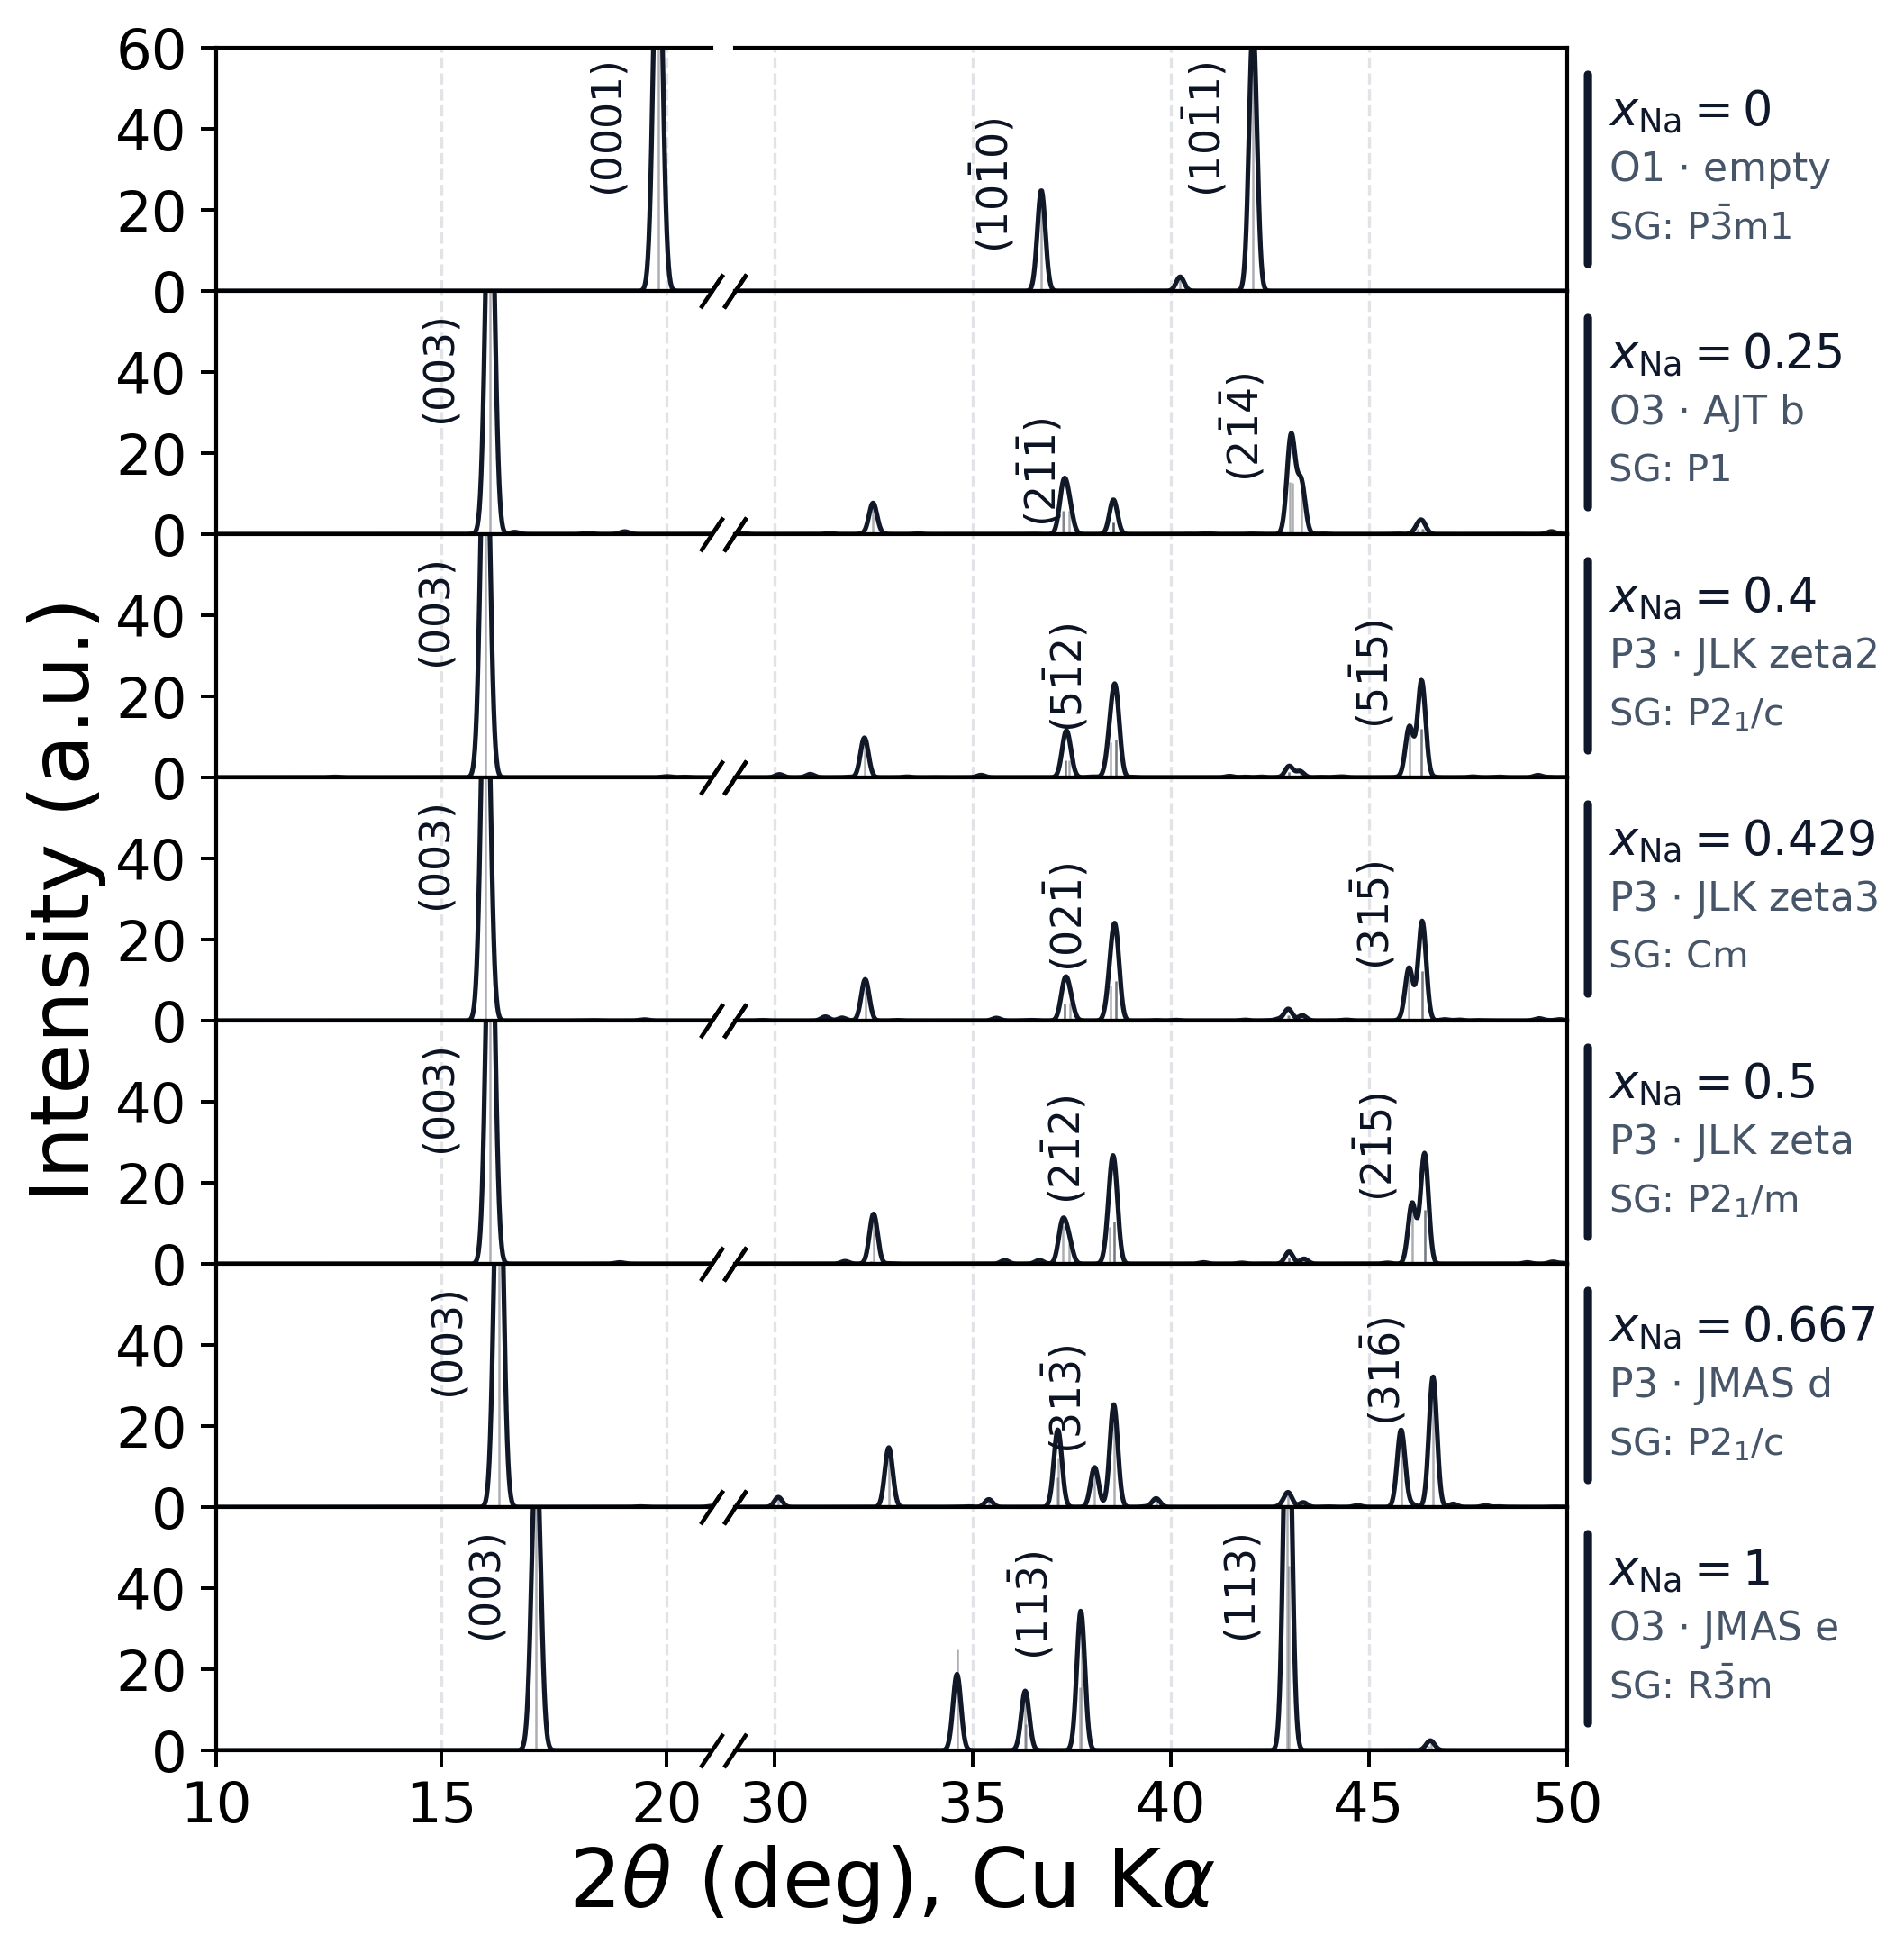

Plotted keys:
  O1_orderings-empty-Co
  O3_orderings-AJT_b_w_vac-Co
  P3_orderings-JLK_zeta2_w_vac-Co
  P3_orderings-JLK_zeta3_w_vac-Co
  P3_orderings-JLK_zeta_w_vac-Co
  P3_orderings-JMAS_d-Co
  O3_orderings-JMAS_e-Co
Gaussian broadening: sigma=0.100 deg, FWHM~0.235 deg, step=0.020 deg


In [31]:
# XRD: Nax(TM)O2 hull structures (singleTM)
# Layout strategy: every subplot row has a FIXED size in inches, and the total
# figure size is computed as (margins_in + n_rows * row_height_in). All title
# positions are therefore independent of n_rows: they are computed from the
# fixed margins, not from figure-fraction guesses.

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from pymatgen.core.structure import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer
import re

hull_csv = Path('../data/singleTM_hull_points.csv')
structures_json = Path('../data/structures.json')

target_tm = 'Co'
dpi = 300

# Broken-axis windows
x1_min, x1_max = 10, 21
x2_min, x2_max = 29, 50

# Gaussian broadening
use_gaussian_broadening = True
sigma_deg = 0.10
x_step_deg = 0.02

# Number of top smeared peaks to annotate with their (hkl) labels.
N_PEAKS_TO_ANNOTATE = 3
# When a peak is taller than this threshold (in I a.u.), the (hkl) label is
# shifted slightly to the left so it doesn't sit on top of the peak.
TALL_PEAK_THRESHOLD = 20.0
TALL_PEAK_X_OFFSET  = 0.6   # 2-theta degrees to shift left for tall peaks

# ---- Fixed inch-based layout (all positions derive from these) ------------
SUBPLOT_H_IN     = 0.9   # height of one row, in inches
DATA_W_IN        = 5.00   # combined width of (left panel + gap + right panel)
LEFT_MARGIN_IN   = 1.20   # space for y tick labels + y-axis title
RIGHT_MARGIN_IN  = 1.55   # space for the side legend (xNa, phase, ordering)
TOP_MARGIN_IN    = 0.12
BOTTOM_MARGIN_IN = 0.95   # space for x tick labels + x-axis title
YLABEL_OFFSET_IN = 0.70   # 'I (a.u.)' distance left of the data area
XLABEL_OFFSET_IN = 0.65   # x-axis title distance below the data area
# ---------------------------------------------------------------------------

# Major xticks to use on EVERY row (not just the bottom one), so the dashed
# grid lines render at all of these positions in every panel.
XTICKS_LEFT  = [10, 15, 20]
XTICKS_RIGHT = [30, 35, 40, 45, 50]

hull = pd.read_csv(hull_csv)
pair_hull = hull[hull['tm'].astype(str) == target_tm].copy()
pair_hull['hull_order'] = pd.to_numeric(pair_hull['hull_order'], errors='coerce')
pair_hull['xNa'] = pd.to_numeric(pair_hull['xNa'], errors='coerce')
pair_hull = pair_hull.sort_values(['hull_order']).reset_index(drop=True)

if pair_hull.empty:
    raise RuntimeError(f'No hull points found for tm={target_tm} in {hull_csv}')

pair_hull['key'] = pair_hull.apply(
    lambda r: f"{r['phase']}-{r['ordering']}-{r['tm']}",
    axis=1,
)

with structures_json.open() as f:
    all_structures = json.load(f)

missing = [k for k in pair_hull['key'] if k not in all_structures]
if missing:
    print('Missing keys (skipped):')
    for k in missing:
        print('  ', k)

pair_hull = pair_hull[pair_hull['key'].isin(all_structures)].copy().reset_index(drop=True)
if pair_hull.empty:
    raise RuntimeError('All selected hull keys are missing in structures.json')

calc = XRDCalculator(wavelength='CuKa')


def short_phase(phase_name):
    return str(phase_name).replace('_orderings', '')


_GREEK = {
    'alpha': r'$\alpha$', 'beta': r'$\beta$', 'gamma': r'$\gamma$', 'delta': r'$\delta$',
    'epsilon': r'$\varepsilon$', 'zeta': r'$\zeta$', 'eta': r'$\eta$', 'theta': r'$\theta$',
    'iota': r'$\iota$', 'kappa': r'$\kappa$', 'lambda': r'$\lambda$', 'mu': r'$\mu$',
    'nu': r'$\nu$', 'xi': r'$\xi$', 'pi': r'$\pi$', 'rho': r'$\rho$', 'sigma': r'$\sigma$',
    'tau': r'$\tau$', 'phi': r'$\varphi$', 'chi': r'$\chi$', 'psi': r'$\psi$', 'omega': r'$\omega$',
}


def pretty_ordering(name):
    """JLK_zeta_w_vac -> 'JLK zeta' (underscores -> spaces; no Greek conversion)."""
    s = str(name).replace('_w_vac', '')
    return s.replace('_', ' ')


def format_spacegroup(sg):
    """Render a Hermann-Mauguin spacegroup symbol with bars/subscripts via
    mathtext, e.g. 'R-3m' -> 'R$\\bar{3}$m', 'P6_3/mmc' -> 'P6$_{3}$/mmc'."""
    s = str(sg)
    s = re.sub(r'-([0-9])', r'$\\bar{\1}$', s)
    s = re.sub(r'([0-9])_([0-9]+)', r'\1$_{\2}$', s)
    return s


def format_hkl(hkl_tuple):
    """Render a Miller (or Miller-Bravais) tuple with no spaces between
    indices and bar notation for negatives, e.g. (1, 0, -1, 1) -> '(10\\bar{1}1)'."""
    parts = []
    for v in hkl_tuple:
        iv = int(round(float(v)))
        if iv < 0:
            parts.append(rf"\bar{{{abs(iv)}}}")
        else:
            parts.append(str(iv))
    return r"$(" + "".join(parts) + r")$"


def gaussian_broadened_profile(x_peaks, y_peaks, x_grid, sigma):
    profile = np.zeros_like(x_grid, dtype=float)
    if sigma <= 0:
        return profile
    for xp, yp in zip(x_peaks, y_peaks):
        profile += yp * np.exp(-0.5 * ((x_grid - xp) / sigma) ** 2)

    max_stick = float(np.max(y_peaks)) if len(y_peaks) else 0.0
    max_prof = float(np.max(profile)) if len(profile) else 0.0
    if max_stick > 0 and max_prof > 0:
        profile *= max_stick / max_prof
    return profile


def top_smeared_peaks(x_grid, y_grid, mask, n_top):
    """Find local maxima of the smeared profile within the boolean ``mask``,
    sorted by descending height. Returns at most ``n_top`` (x, y) tuples."""
    x_vis = x_grid[mask]
    y_vis = y_grid[mask]
    if x_vis.size == 0:
        return []
    peak_idx, _ = find_peaks(y_vis)
    if peak_idx.size == 0:
        return [(float(x_vis[int(np.argmax(y_vis))]), float(np.max(y_vis)))]
    order = peak_idx[np.argsort(y_vis[peak_idx])[::-1]]
    return [(float(x_vis[i]), float(y_vis[i])) for i in order[:n_top]]


def render_xrd_figure(pair_hull_df, all_structures, calc):
    """Build a (n x 2) broken-axis XRD figure with fixed-inch row size.
    Returns (fig, axes). Caller decides whether to show or save."""
    n = len(pair_hull_df)

    fig_w_in = LEFT_MARGIN_IN + DATA_W_IN + RIGHT_MARGIN_IN
    fig_h_in = TOP_MARGIN_IN + n * SUBPLOT_H_IN + BOTTOM_MARGIN_IN

    fig, axes = plt.subplots(
        n, 2,
        figsize=(fig_w_in, fig_h_in),
        dpi=dpi,
        gridspec_kw={'hspace': 0.0, 'wspace': 0.035, 'width_ratios': [1.12, 1.88]},
    )
    if n == 1:
        axes = np.array([axes])

    fig_left   = LEFT_MARGIN_IN / fig_w_in
    fig_right  = 1.0 - RIGHT_MARGIN_IN / fig_w_in
    fig_bottom = BOTTOM_MARGIN_IN / fig_h_in
    fig_top    = 1.0 - TOP_MARGIN_IN / fig_h_in

    for idx, (_, row) in enumerate(pair_hull_df.iterrows()):
        ax_l = axes[idx, 0]
        ax_r = axes[idx, 1]

        structure = Structure.from_dict(all_structures[row['key']])
        pattern = calc.get_pattern(structure, two_theta_range=(0, 90))
        x = np.array(pattern.x, dtype=float)
        y = np.array(pattern.y, dtype=float)

        m1 = (x >= x1_min) & (x <= x1_max)
        m2 = (x >= x2_min) & (x <= x2_max)

        if use_gaussian_broadening:
            x_grid = np.arange(0.0, 90.0 + x_step_deg, x_step_deg)
            y_grid = gaussian_broadened_profile(x, y, x_grid, sigma=sigma_deg)
            g1 = (x_grid >= x1_min) & (x_grid <= x1_max)
            g2 = (x_grid >= x2_min) & (x_grid <= x2_max)

            ax_l.plot(x_grid[g1], y_grid[g1], color='#111827', linewidth=1.25)
            ax_r.plot(x_grid[g2], y_grid[g2], color='#111827', linewidth=1.25)
            ax_l.vlines(x[m1], 0, y[m1], color='#111827', linewidth=0.6, alpha=0.35)
            ax_r.vlines(x[m2], 0, y[m2], color='#111827', linewidth=0.6, alpha=0.35)
        else:
            ax_l.vlines(x[m1], 0, y[m1], color='#111827', linewidth=1.2)
            ax_r.vlines(x[m2], 0, y[m2], color='#111827', linewidth=1.2)

        yticks_this = [0, 20, 40, 60] if idx == 0 else [0, 20, 40]
        for ax in (ax_l, ax_r):
            ax.set_ylim(0, 60)
            ax.set_yticks(yticks_this)
            ax.tick_params(axis='both', labelsize=15.0, length=4.2, width=0.95)
            ax.grid(axis='x', linestyle='--', alpha=0.3, color='#9ca3af')
            ax.spines['top'].set_visible(True)
            ax.spines['top'].set_linewidth(1.0)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            ax.spines['right'].set_linewidth(1.0)

        ax_l.set_xlim(x1_min, x1_max)
        ax_r.set_xlim(x2_min, x2_max)
        ax_l.set_xticks(XTICKS_LEFT)
        ax_r.set_xticks(XTICKS_RIGHT)
        ax_l.set_ylabel('')
        ax_r.tick_params(axis='y', left=False, labelleft=False)
        ax_r.spines['left'].set_visible(False)
        ax_l.spines['right'].set_visible(False)

        # ---- Annotate top-N smeared peaks with their (hkl) from the stick data ----
        if use_gaussian_broadening and len(x) > 0:
            visible_mask = g1 | g2
            top_peaks = top_smeared_peaks(x_grid, y_grid, visible_mask, N_PEAKS_TO_ANNOTATE)
            for peak_x, peak_y in top_peaks:
                stick_i = int(np.argmin(np.abs(x - peak_x)))
                hkl_tuple = pattern.hkls[stick_i][0]['hkl']
                hkl_str = format_hkl(hkl_tuple)

                if x1_min <= peak_x <= x1_max:
                    target_ax = ax_l
                elif x2_min <= peak_x <= x2_max:
                    target_ax = ax_r
                else:
                    continue

                # Rotated label. For tall peaks (intensity > threshold) the
                # label is shifted slightly to the left of the peak so it does
                # not sit on top of the peak; otherwise it goes just above.
                if peak_y > TALL_PEAK_THRESHOLD:
                    x_anchor = peak_x - TALL_PEAK_X_OFFSET
                else:
                    x_anchor = peak_x
                y_anchor = min(peak_y + 1.5, 40.0)

                target_ax.text(
                    x_anchor, y_anchor, hkl_str,
                    ha='center', va='bottom',
                    rotation=90, rotation_mode='anchor',
                    fontsize=11.0, color="#0b1222",
                )

        phase_label = short_phase(row['phase'])
        ord_label = pretty_ordering(row['ordering'])
        spg_symbol = SpacegroupAnalyzer(structure).get_space_group_symbol()
        spg_label = format_spacegroup(spg_symbol)
        primary = rf"$\mathit{{x}}_{{\mathrm{{Na}}}} = {row['xNa']:.3g}$"
        secondary = rf"{phase_label} $\cdot$ {ord_label}"
        tertiary = rf"SG: {spg_label}"

        ax_r.annotate(
            '',
            xy=(1.025, 0.08), xycoords='axes fraction',
            xytext=(1.025, 0.92), textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-', color='#0f172a', linewidth=2.2),
        )
        ax_r.text(1.05, 0.74, primary, transform=ax_r.transAxes,
                  ha='left', va='center', fontsize=12.6, color='#0f172a')
        ax_r.text(1.05, 0.50, secondary, transform=ax_r.transAxes,
                  ha='left', va='center', fontsize=10.6, color='#475569')
        ax_r.text(1.05, 0.26, tertiary, transform=ax_r.transAxes,
                  ha='left', va='center', fontsize=10.0, color='#475569')

    d_slope = 1.5
    mark_kw = dict(marker=[(-1, -d_slope), (1, d_slope)], markersize=9,
                   linestyle='none', color='k', mec='k', mew=1.1, clip_on=False)
    for idx in range(n):
        ax_l = axes[idx, 0]
        ax_r = axes[idx, 1]
        ax_l.plot([1], [0], transform=ax_l.transAxes, **mark_kw)
        ax_r.plot([0], [0], transform=ax_r.transAxes, **mark_kw)
        if idx > 0:
            ax_l.plot([1], [1], transform=ax_l.transAxes, **mark_kw)
            ax_r.plot([0], [1], transform=ax_r.transAxes, **mark_kw)
        if idx < n - 1:
            ax_l.tick_params(axis='x', labelbottom=False)
            ax_r.tick_params(axis='x', labelbottom=False)

    xlabel_x = 0.5 * (fig_left + fig_right)
    xlabel_y = (BOTTOM_MARGIN_IN - XLABEL_OFFSET_IN) / fig_h_in
    ylabel_x = (LEFT_MARGIN_IN - YLABEL_OFFSET_IN) / fig_w_in
    ylabel_y = 0.5 * (fig_bottom + fig_top)

    fig.supxlabel(r'2$\theta$ (deg), Cu K$\alpha$', fontsize=22.0,
                  x=xlabel_x, y=xlabel_y)
    fig.supylabel('Intensity (a.u.)', fontsize=22.0,
                  x=ylabel_x, y=ylabel_y)

    fig.subplots_adjust(left=fig_left, right=fig_right,
                        top=fig_top, bottom=fig_bottom,
                        hspace=0.0, wspace=0.035)
    return fig, axes


fig, axes = render_xrd_figure(pair_hull, all_structures, calc)
plt.show()

print('Plotted keys:')
for k in pair_hull['key']:
    print(' ', k)

if use_gaussian_broadening:
    fwhm = 2.3548 * sigma_deg
    print(f'Gaussian broadening: sigma={sigma_deg:.3f} deg, FWHM~{fwhm:.3f} deg, step={x_step_deg:.3f} deg')


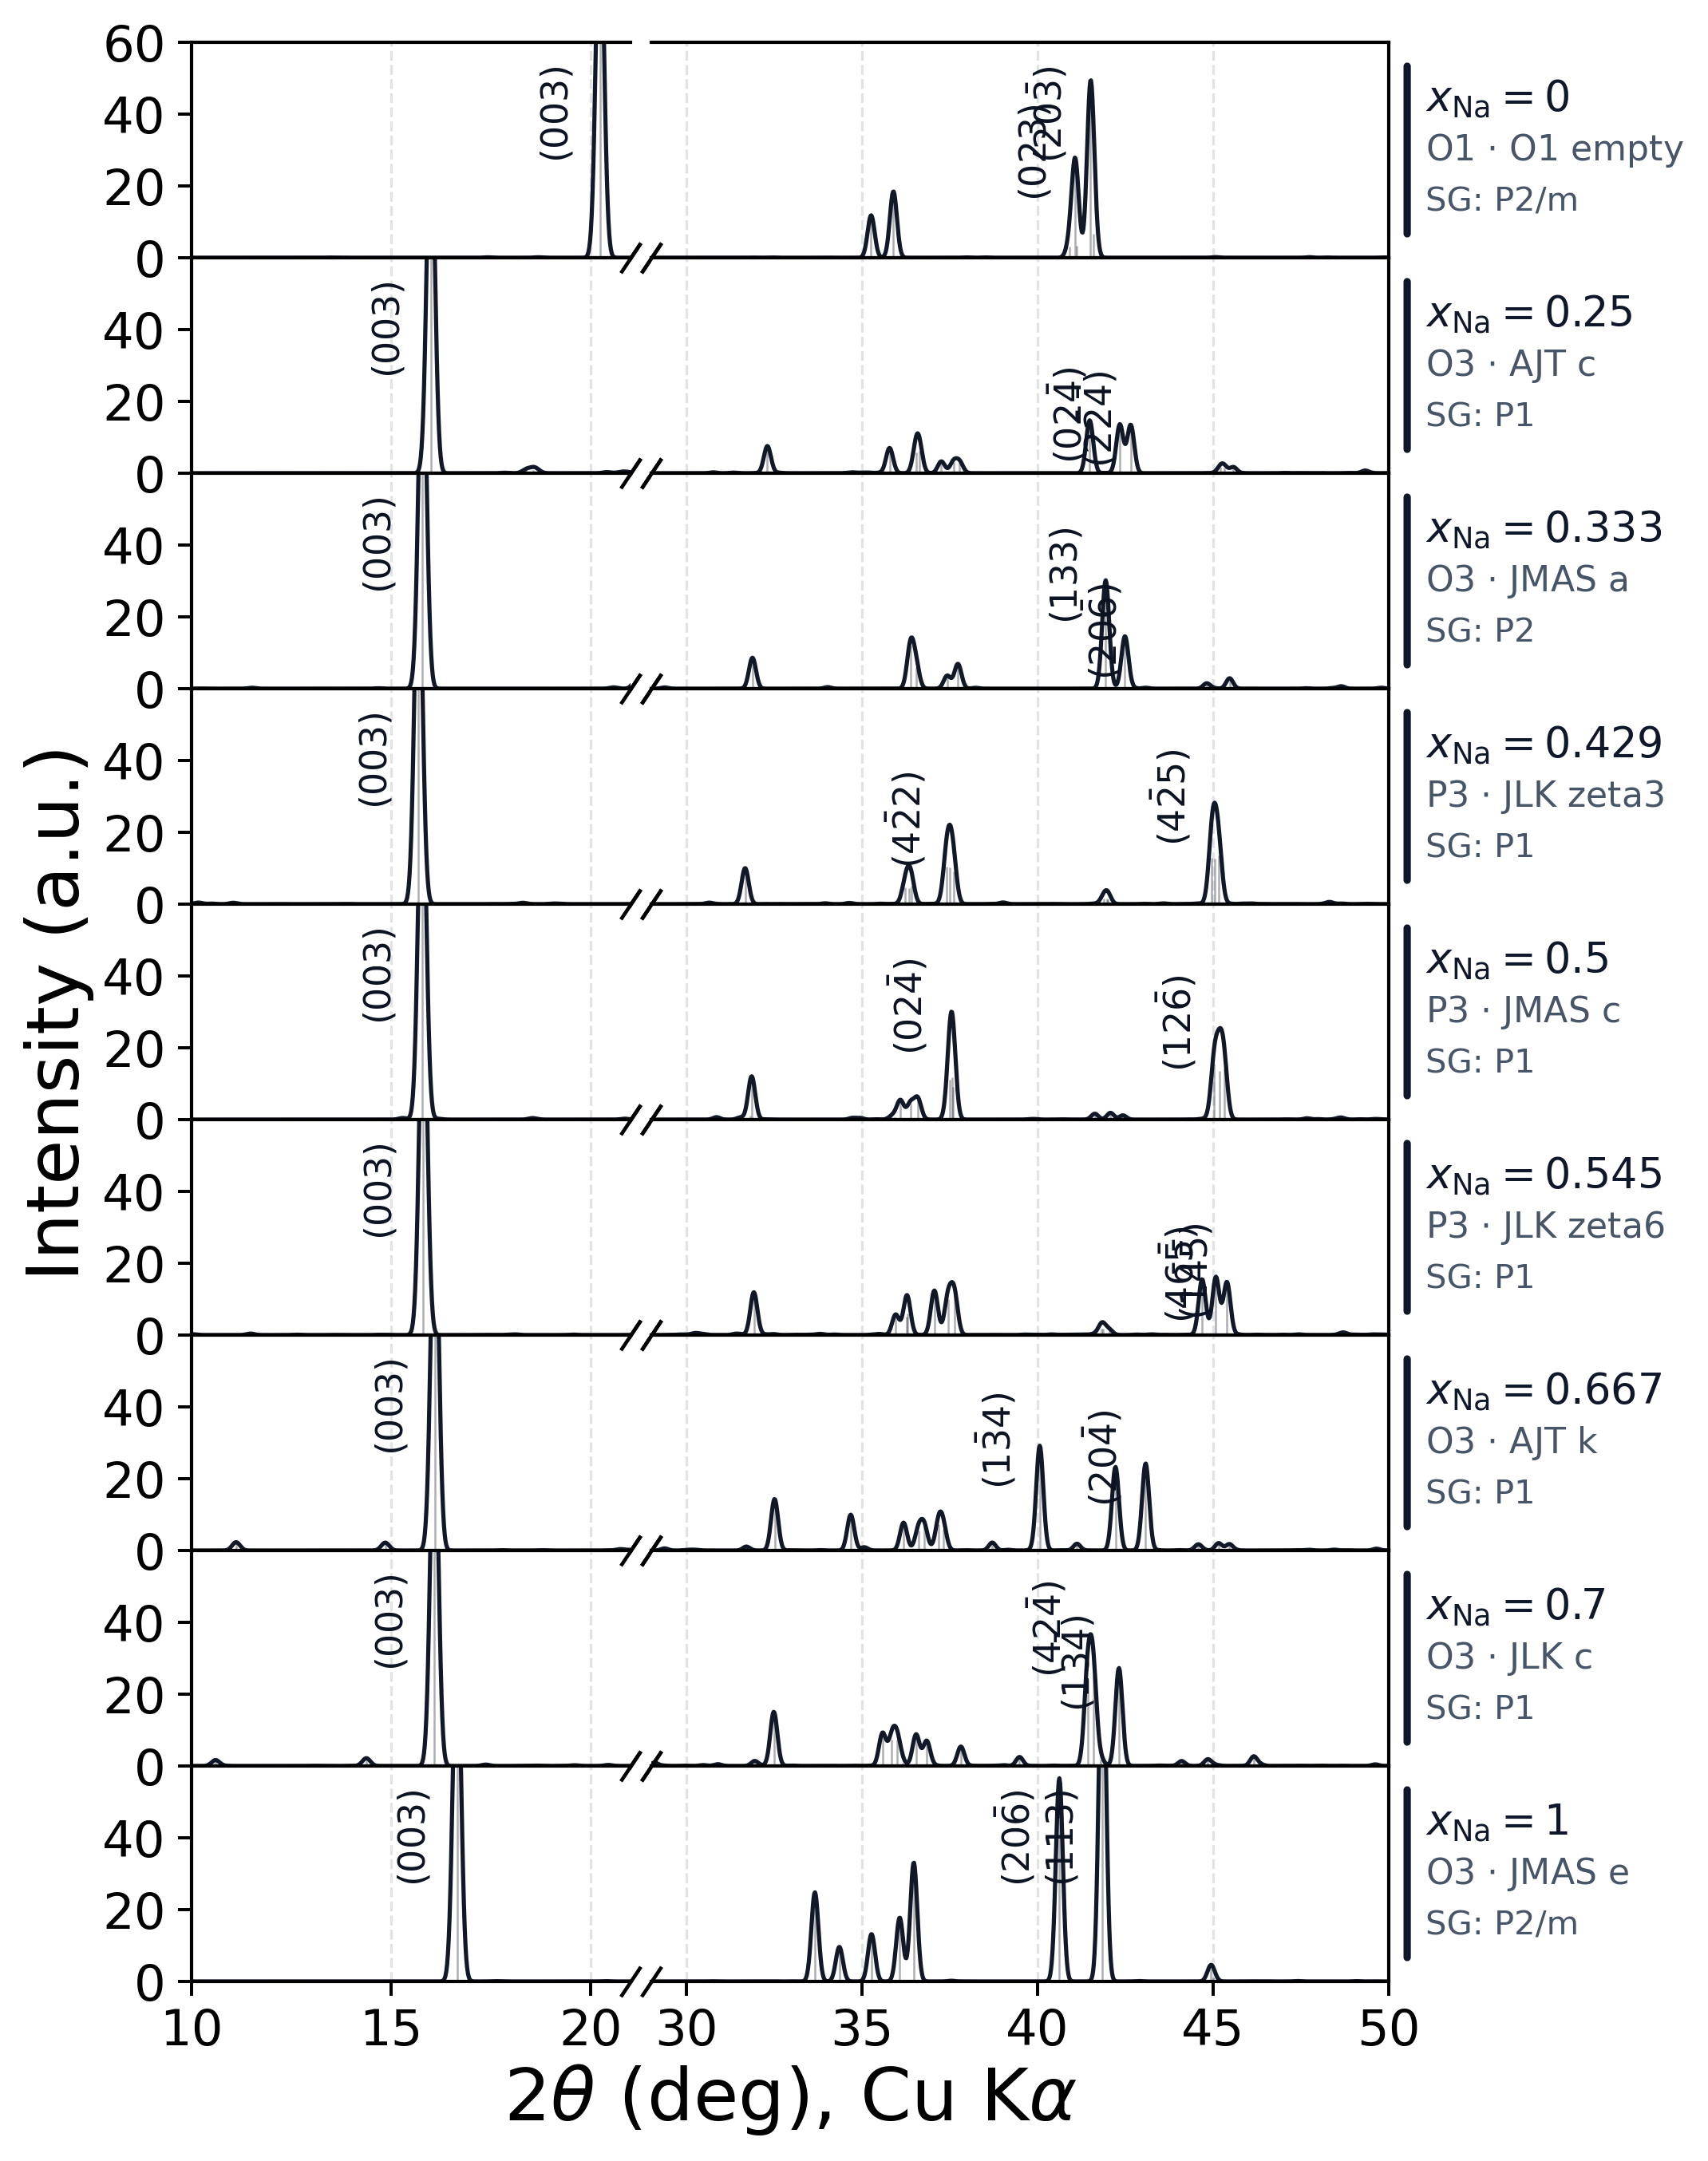

Plotted keys:
  O1_orderings-O1_empty-Fe_Ni-elec_1
  O3_orderings-AJT_c_w_vac-Fe_Ni-elec_0
  O3_orderings-JMAS_a-Fe_Ni-elec_1
  P3_orderings-JLK_zeta3_w_vac-Fe_Ni-elec_1
  P3_orderings-JMAS_c-Fe_Ni-elec_1
  P3_orderings-JLK_zeta6_w_vac-Fe_Ni-elec_0
  O3_orderings-AJT_k_w_vac-Fe_Ni-elec_0
  O3_orderings-JLK_c_w_vac-Fe_Ni-elec_0
  O3_orderings-JMAS_e-Fe_Ni-elec_1
Gaussian broadening: sigma=0.100 deg, FWHM~0.235 deg, step=0.020 deg


In [32]:
# XRD: Nax(TM_pair)O2 hull structures (doubleTM)
# Layout strategy: every subplot row has a FIXED size in inches, and the total
# figure size is computed as (margins_in + n_rows * row_height_in). All title
# positions are therefore independent of n_rows: they are computed from the
# fixed margins, not from figure-fraction guesses.

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from pymatgen.core.structure import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer
import re

hull_csv = Path('../data/doubleTM_hull_points.csv')
structures_json = Path('../data/structures.json')

target_pair = 'Fe_Ni'
dpi = 300

# Broken-axis windows
x1_min, x1_max = 10, 21
x2_min, x2_max = 29, 50

# Gaussian broadening
use_gaussian_broadening = True
sigma_deg = 0.10
x_step_deg = 0.02

# Number of top smeared peaks to annotate with their (hkl) labels.
N_PEAKS_TO_ANNOTATE = 3
# When a peak is taller than this threshold (in I a.u.), the (hkl) label is
# shifted slightly to the left so it doesn't sit on top of the peak.
TALL_PEAK_THRESHOLD = 20.0
TALL_PEAK_X_OFFSET  = 0.6   # 2-theta degrees to shift left for tall peaks

# ---- Fixed inch-based layout (all positions derive from these) ------------
SUBPLOT_H_IN     = 0.9   # height of one row, in inches
DATA_W_IN        = 5.00   # combined width of (left panel + gap + right panel)
LEFT_MARGIN_IN   = 1.20   # space for y tick labels + y-axis title
RIGHT_MARGIN_IN  = 1.55   # space for the side legend (xNa, phase, ordering)
TOP_MARGIN_IN    = 0.12
BOTTOM_MARGIN_IN = 0.95   # space for x tick labels + x-axis title
YLABEL_OFFSET_IN = 0.70   # 'I (a.u.)' distance left of the data area
XLABEL_OFFSET_IN = 0.65   # x-axis title distance below the data area
# ---------------------------------------------------------------------------

# Major xticks to use on EVERY row (not just the bottom one), so the dashed
# grid lines render at all of these positions in every panel.
XTICKS_LEFT  = [10, 15, 20]
XTICKS_RIGHT = [30, 35, 40, 45, 50]

hull = pd.read_csv(hull_csv)
pair_hull = hull[hull['tm_pair'].astype(str) == target_pair].copy()
pair_hull['hull_order'] = pd.to_numeric(pair_hull['hull_order'], errors='coerce')
pair_hull['xNa'] = pd.to_numeric(pair_hull['xNa'], errors='coerce')
pair_hull['elec'] = pair_hull['elec'].astype(str)
pair_hull = pair_hull.sort_values(['hull_order', 'elec']).reset_index(drop=True)

if pair_hull.empty:
    raise RuntimeError(f'No hull points found for tm_pair={target_pair} in {hull_csv}')

pair_hull['key'] = pair_hull.apply(
    lambda r: f"{r['phase']}-{r['ordering']}-{r['tm_pair']}-{r['elec']}",
    axis=1,
)

with structures_json.open() as f:
    all_structures = json.load(f)

missing = [k for k in pair_hull['key'] if k not in all_structures]
if missing:
    print('Missing keys (skipped):')
    for k in missing:
        print('  ', k)

pair_hull = pair_hull[pair_hull['key'].isin(all_structures)].copy().reset_index(drop=True)
if pair_hull.empty:
    raise RuntimeError('All selected hull keys are missing in structures.json')

calc = XRDCalculator(wavelength='CuKa')


def short_phase(phase_name):
    return str(phase_name).replace('_orderings', '')


_GREEK = {
    'alpha': r'$\alpha$', 'beta': r'$\beta$', 'gamma': r'$\gamma$', 'delta': r'$\delta$',
    'epsilon': r'$\varepsilon$', 'zeta': r'$\zeta$', 'eta': r'$\eta$', 'theta': r'$\theta$',
    'iota': r'$\iota$', 'kappa': r'$\kappa$', 'lambda': r'$\lambda$', 'mu': r'$\mu$',
    'nu': r'$\nu$', 'xi': r'$\xi$', 'pi': r'$\pi$', 'rho': r'$\rho$', 'sigma': r'$\sigma$',
    'tau': r'$\tau$', 'phi': r'$\varphi$', 'chi': r'$\chi$', 'psi': r'$\psi$', 'omega': r'$\omega$',
}


def pretty_ordering(name):
    """JLK_zeta_w_vac -> 'JLK zeta' (underscores -> spaces; no Greek conversion)."""
    s = str(name).replace('_w_vac', '')
    return s.replace('_', ' ')


def format_spacegroup(sg):
    """Render a Hermann-Mauguin spacegroup symbol with bars/subscripts via
    mathtext, e.g. 'R-3m' -> 'R$\\bar{3}$m', 'P6_3/mmc' -> 'P6$_{3}$/mmc'."""
    s = str(sg)
    s = re.sub(r'-([0-9])', r'$\\bar{\1}$', s)
    s = re.sub(r'([0-9])_([0-9]+)', r'\1$_{\2}$', s)
    return s


def format_hkl(hkl_tuple):
    """Render a Miller (or Miller-Bravais) tuple with no spaces between
    indices and bar notation for negatives, e.g. (1, 0, -1, 1) -> '(10\\bar{1}1)'."""
    parts = []
    for v in hkl_tuple:
        iv = int(round(float(v)))
        if iv < 0:
            parts.append(rf"\bar{{{abs(iv)}}}")
        else:
            parts.append(str(iv))
    return r"$(" + "".join(parts) + r")$"


def gaussian_broadened_profile(x_peaks, y_peaks, x_grid, sigma):
    profile = np.zeros_like(x_grid, dtype=float)
    if sigma <= 0:
        return profile
    for xp, yp in zip(x_peaks, y_peaks):
        profile += yp * np.exp(-0.5 * ((x_grid - xp) / sigma) ** 2)

    max_stick = float(np.max(y_peaks)) if len(y_peaks) else 0.0
    max_prof = float(np.max(profile)) if len(profile) else 0.0
    if max_stick > 0 and max_prof > 0:
        profile *= max_stick / max_prof
    return profile


def top_smeared_peaks(x_grid, y_grid, mask, n_top):
    """Find local maxima of the smeared profile within the boolean ``mask``,
    sorted by descending height. Returns at most ``n_top`` (x, y) tuples."""
    x_vis = x_grid[mask]
    y_vis = y_grid[mask]
    if x_vis.size == 0:
        return []
    peak_idx, _ = find_peaks(y_vis)
    if peak_idx.size == 0:
        return [(float(x_vis[int(np.argmax(y_vis))]), float(np.max(y_vis)))]
    order = peak_idx[np.argsort(y_vis[peak_idx])[::-1]]
    return [(float(x_vis[i]), float(y_vis[i])) for i in order[:n_top]]


def render_xrd_figure(pair_hull_df, all_structures, calc):
    """Build a (n x 2) broken-axis XRD figure with fixed-inch row size.
    Returns (fig, axes). Caller decides whether to show or save."""
    n = len(pair_hull_df)

    fig_w_in = LEFT_MARGIN_IN + DATA_W_IN + RIGHT_MARGIN_IN
    fig_h_in = TOP_MARGIN_IN + n * SUBPLOT_H_IN + BOTTOM_MARGIN_IN

    fig, axes = plt.subplots(
        n, 2,
        figsize=(fig_w_in, fig_h_in),
        dpi=dpi,
        gridspec_kw={'hspace': 0.0, 'wspace': 0.035, 'width_ratios': [1.12, 1.88]},
    )
    if n == 1:
        axes = np.array([axes])

    fig_left   = LEFT_MARGIN_IN / fig_w_in
    fig_right  = 1.0 - RIGHT_MARGIN_IN / fig_w_in
    fig_bottom = BOTTOM_MARGIN_IN / fig_h_in
    fig_top    = 1.0 - TOP_MARGIN_IN / fig_h_in

    for idx, (_, row) in enumerate(pair_hull_df.iterrows()):
        ax_l = axes[idx, 0]
        ax_r = axes[idx, 1]

        structure = Structure.from_dict(all_structures[row['key']])
        pattern = calc.get_pattern(structure, two_theta_range=(0, 90))
        x = np.array(pattern.x, dtype=float)
        y = np.array(pattern.y, dtype=float)

        m1 = (x >= x1_min) & (x <= x1_max)
        m2 = (x >= x2_min) & (x <= x2_max)

        if use_gaussian_broadening:
            x_grid = np.arange(0.0, 90.0 + x_step_deg, x_step_deg)
            y_grid = gaussian_broadened_profile(x, y, x_grid, sigma=sigma_deg)
            g1 = (x_grid >= x1_min) & (x_grid <= x1_max)
            g2 = (x_grid >= x2_min) & (x_grid <= x2_max)

            ax_l.plot(x_grid[g1], y_grid[g1], color='#111827', linewidth=1.25)
            ax_r.plot(x_grid[g2], y_grid[g2], color='#111827', linewidth=1.25)
            ax_l.vlines(x[m1], 0, y[m1], color='#111827', linewidth=0.6, alpha=0.35)
            ax_r.vlines(x[m2], 0, y[m2], color='#111827', linewidth=0.6, alpha=0.35)
        else:
            ax_l.vlines(x[m1], 0, y[m1], color='#111827', linewidth=1.2)
            ax_r.vlines(x[m2], 0, y[m2], color='#111827', linewidth=1.2)

        yticks_this = [0, 20, 40, 60] if idx == 0 else [0, 20, 40]
        for ax in (ax_l, ax_r):
            ax.set_ylim(0, 60)
            ax.set_yticks(yticks_this)
            ax.tick_params(axis='both', labelsize=15.0, length=4.2, width=0.95)
            ax.grid(axis='x', linestyle='--', alpha=0.3, color='#9ca3af')
            ax.spines['top'].set_visible(True)
            ax.spines['top'].set_linewidth(1.0)
            ax.spines['left'].set_linewidth(1.0)
            ax.spines['bottom'].set_linewidth(1.0)
            ax.spines['right'].set_linewidth(1.0)

        ax_l.set_xlim(x1_min, x1_max)
        ax_r.set_xlim(x2_min, x2_max)
        ax_l.set_xticks(XTICKS_LEFT)
        ax_r.set_xticks(XTICKS_RIGHT)
        ax_l.set_ylabel('')
        ax_r.tick_params(axis='y', left=False, labelleft=False)
        ax_r.spines['left'].set_visible(False)
        ax_l.spines['right'].set_visible(False)

        # ---- Annotate top-N smeared peaks with their (hkl) from the stick data ----
        if use_gaussian_broadening and len(x) > 0:
            visible_mask = g1 | g2
            top_peaks = top_smeared_peaks(x_grid, y_grid, visible_mask, N_PEAKS_TO_ANNOTATE)
            for peak_x, peak_y in top_peaks:
                stick_i = int(np.argmin(np.abs(x - peak_x)))
                hkl_tuple = pattern.hkls[stick_i][0]['hkl']
                hkl_str = format_hkl(hkl_tuple)

                if x1_min <= peak_x <= x1_max:
                    target_ax = ax_l
                elif x2_min <= peak_x <= x2_max:
                    target_ax = ax_r
                else:
                    continue

                # Rotated label. For tall peaks (intensity > threshold) the
                # label is shifted slightly to the left of the peak so it does
                # not sit on top of the peak; otherwise it goes just above.
                if peak_y > TALL_PEAK_THRESHOLD:
                    x_anchor = peak_x - TALL_PEAK_X_OFFSET
                else:
                    x_anchor = peak_x
                y_anchor = min(peak_y + 1.5, 40.0)

                target_ax.text(
                    x_anchor, y_anchor, hkl_str,
                    ha='center', va='bottom',
                    rotation=90, rotation_mode='anchor',
                    fontsize=11.0, color="#0b1222",
                )

        phase_label = short_phase(row['phase'])
        ord_label = pretty_ordering(row['ordering'])
        spg_symbol = SpacegroupAnalyzer(structure).get_space_group_symbol()
        spg_label = format_spacegroup(spg_symbol)
        primary = rf"$\mathit{{x}}_{{\mathrm{{Na}}}} = {row['xNa']:.3g}$"
        secondary = rf"{phase_label} $\cdot$ {ord_label}"
        tertiary = rf"SG: {spg_label}"

        ax_r.annotate(
            '',
            xy=(1.025, 0.08), xycoords='axes fraction',
            xytext=(1.025, 0.92), textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-', color='#0f172a', linewidth=2.2),
        )
        ax_r.text(1.05, 0.74, primary, transform=ax_r.transAxes,
                  ha='left', va='center', fontsize=12.6, color='#0f172a')
        ax_r.text(1.05, 0.50, secondary, transform=ax_r.transAxes,
                  ha='left', va='center', fontsize=10.6, color='#475569')
        ax_r.text(1.05, 0.26, tertiary, transform=ax_r.transAxes,
                  ha='left', va='center', fontsize=10.0, color='#475569')

    d_slope = 1.5
    mark_kw = dict(marker=[(-1, -d_slope), (1, d_slope)], markersize=9,
                   linestyle='none', color='k', mec='k', mew=1.1, clip_on=False)
    for idx in range(n):
        ax_l = axes[idx, 0]
        ax_r = axes[idx, 1]
        ax_l.plot([1], [0], transform=ax_l.transAxes, **mark_kw)
        ax_r.plot([0], [0], transform=ax_r.transAxes, **mark_kw)
        if idx > 0:
            ax_l.plot([1], [1], transform=ax_l.transAxes, **mark_kw)
            ax_r.plot([0], [1], transform=ax_r.transAxes, **mark_kw)
        if idx < n - 1:
            ax_l.tick_params(axis='x', labelbottom=False)
            ax_r.tick_params(axis='x', labelbottom=False)

    xlabel_x = 0.5 * (fig_left + fig_right)
    xlabel_y = (BOTTOM_MARGIN_IN - XLABEL_OFFSET_IN) / fig_h_in
    ylabel_x = (LEFT_MARGIN_IN - YLABEL_OFFSET_IN) / fig_w_in
    ylabel_y = 0.5 * (fig_bottom + fig_top)

    fig.supxlabel(r'2$\theta$ (deg), Cu K$\alpha$', fontsize=22.0,
                  x=xlabel_x, y=xlabel_y)
    fig.supylabel('Intensity (a.u.)', fontsize=22.0,
                  x=ylabel_x, y=ylabel_y)

    fig.subplots_adjust(left=fig_left, right=fig_right,
                        top=fig_top, bottom=fig_bottom,
                        hspace=0.0, wspace=0.035)
    return fig, axes


fig, axes = render_xrd_figure(pair_hull, all_structures, calc)
plt.show()

print('Plotted keys:')
for k in pair_hull['key']:
    print(' ', k)

if use_gaussian_broadening:
    fwhm = 2.3548 * sigma_deg
    print(f'Gaussian broadening: sigma={sigma_deg:.3f} deg, FWHM~{fwhm:.3f} deg, step={x_step_deg:.3f} deg')


In [33]:
# Batch generate XRD figures for ALL doubleTM tm_pairs and singleTM tms,
# saving as PDF under ../data/figures/xrd_pattern/.
# Reuses the inch-fixed `render_xrd_figure` defined in the previous cell, so
# every saved figure has the SAME row size and the SAME title placement
# regardless of how many hull points each pair/tm has.

from pathlib import Path

out_dir = Path('../data/figures/xrd_pattern')
out_dir.mkdir(parents=True, exist_ok=True)

# Hull tables (the doubleTM `hull` was loaded by the previous cell).
single_hull = pd.read_csv(Path('../data/singleTM_hull_points.csv'))


def build_pair_hull(target_pair):
    sub = hull[hull['tm_pair'].astype(str) == target_pair].copy()
    sub['hull_order'] = pd.to_numeric(sub['hull_order'], errors='coerce')
    sub['xNa'] = pd.to_numeric(sub['xNa'], errors='coerce')
    sub['elec'] = sub['elec'].astype(str)
    sub = sub.sort_values(['hull_order', 'elec']).reset_index(drop=True)
    if sub.empty:
        return sub
    sub['key'] = sub.apply(
        lambda r: f"{r['phase']}-{r['ordering']}-{r['tm_pair']}-{r['elec']}",
        axis=1,
    )
    missing = [k for k in sub['key'] if k not in all_structures]
    if missing:
        print(f'[{target_pair}] missing {len(missing)} keys (skipped):')
        for k in missing:
            print('   ', k)
    sub = sub[sub['key'].isin(all_structures)].copy().reset_index(drop=True)
    return sub


def build_single_hull(target_tm):
    """SingleTM analogue of build_pair_hull. Filters singleTM_hull_points by
    `tm`, sorts by hull_order, and constructs the structure key without the
    `tm_pair`/`elec` segments used in the doubleTM case."""
    sub = single_hull[single_hull['tm'].astype(str) == target_tm].copy()
    sub['hull_order'] = pd.to_numeric(sub['hull_order'], errors='coerce')
    sub['xNa'] = pd.to_numeric(sub['xNa'], errors='coerce')
    sub = sub.sort_values(['hull_order']).reset_index(drop=True)
    if sub.empty:
        return sub
    sub['key'] = sub.apply(
        lambda r: f"{r['phase']}-{r['ordering']}-{r['tm']}",
        axis=1,
    )
    missing = [k for k in sub['key'] if k not in all_structures]
    if missing:
        print(f'[{target_tm}] missing {len(missing)} keys (skipped):')
        for k in missing:
            print('   ', k)
    sub = sub[sub['key'].isin(all_structures)].copy().reset_index(drop=True)
    return sub


# ---------------- doubleTM batch ----------------
all_pairs = sorted(hull['tm_pair'].dropna().astype(str).unique())
print(f'Generating XRD figures for {len(all_pairs)} doubleTM pairs into {out_dir.resolve()}')

for pair in all_pairs:
    sub = build_pair_hull(pair)
    if sub.empty:
        print(f'[skip] {pair}: no usable hull points')
        continue

    fig, _ = render_xrd_figure(sub, all_structures, calc)
    out_path = out_dir / f'xrd_{pair}.pdf'
    # Save without bbox_inches='tight' so the on-disk figure preserves the
    # exact inch-based size computed by render_xrd_figure (consistent layout
    # across pairs even though they have different row counts).
    fig.savefig(out_path)
    plt.close(fig)
    print(f'[saved] {pair}: {out_path}  (n={len(sub)})')


# ---------------- singleTM batch ----------------
all_tms = sorted(single_hull['tm'].dropna().astype(str).unique())
print(f'\nGenerating XRD figures for {len(all_tms)} singleTM tms into {out_dir.resolve()}')

for tm in all_tms:
    sub = build_single_hull(tm)
    if sub.empty:
        print(f'[skip] {tm}: no usable hull points')
        continue

    fig, _ = render_xrd_figure(sub, all_structures, calc)
    out_path = out_dir / f'xrd_{tm}.pdf'
    fig.savefig(out_path)
    plt.close(fig)
    print(f'[saved] {tm}: {out_path}  (n={len(sub)})')

print('Done.')


Generating XRD figures for 10 doubleTM pairs into ../data/figures/xrd_pattern
[saved] Co_Ni: ../data/figures/xrd_pattern/xrd_Co_Ni.pdf  (n=9)
[saved] Fe_Co: ../data/figures/xrd_pattern/xrd_Fe_Co.pdf  (n=8)
[saved] Fe_Ni: ../data/figures/xrd_pattern/xrd_Fe_Ni.pdf  (n=9)
[saved] Mn_Co: ../data/figures/xrd_pattern/xrd_Mn_Co.pdf  (n=6)
[saved] Mn_Fe: ../data/figures/xrd_pattern/xrd_Mn_Fe.pdf  (n=6)
[saved] Mn_Ni: ../data/figures/xrd_pattern/xrd_Mn_Ni.pdf  (n=8)
[saved] Ti_Co: ../data/figures/xrd_pattern/xrd_Ti_Co.pdf  (n=5)
[saved] Ti_Fe: ../data/figures/xrd_pattern/xrd_Ti_Fe.pdf  (n=6)
[saved] Ti_Mn: ../data/figures/xrd_pattern/xrd_Ti_Mn.pdf  (n=6)
[saved] Ti_Ni: ../data/figures/xrd_pattern/xrd_Ti_Ni.pdf  (n=6)

Generating XRD figures for 7 singleTM tms into ../data/figures/xrd_pattern
[saved] Co: ../data/figures/xrd_pattern/xrd_Co.pdf  (n=7)
[saved] Cr: ../data/figures/xrd_pattern/xrd_Cr.pdf  (n=5)
[saved] Fe: ../data/figures/xrd_pattern/xrd_Fe.pdf  (n=5)
[saved] Mn: ../data/figures/xrd_

In [7]:
# Step 1: pick the lowest-energy MP-compatible (PBE+U) relaxation for each
# stable hull point. Prefer 2nd relaxation; fall back to 1st when missing.
# Output: in-memory DataFrames `single_energies` and `double_energies`
# (consumed by the next cell). Nothing is written to disk here.
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path('../data')


def best_per_key(path, key_cols):
    """Read a relaxation CSV; keep OK/converged rows; lowest-energy row per key."""
    df = pd.read_csv(path)
    df['energy_eV'] = pd.to_numeric(df['energy_eV'], errors='coerce')
    if 'status' in df:
        df = df[df['status'].astype(str).eq('OK')]
    if 'converged' in df:
        df = df[df['converged'].astype(str).str.lower().eq('true')]
    if 'n_custodian_errors' in df:
        df = df[pd.to_numeric(df['n_custodian_errors'], errors='coerce').fillna(0).eq(0)]
    return (df.dropna(subset=key_cols + ['energy_eV'])
              .sort_values('energy_eV')
              .drop_duplicates(subset=key_cols, keep='first'))


def merge_best(hull_csv, r1_csv, r2_csv, key_cols):
    """Merge hull points with 1st & 2nd relaxation; prefer 2nd, fall back to 1st."""
    keep = key_cols + ['energy_eV', 'energy_per_atom_eV', 'natoms']
    r1 = best_per_key(r1_csv, key_cols)[keep].rename(columns={
        'energy_eV': 'energy_eV_r1',
        'energy_per_atom_eV': 'energy_per_atom_eV_r1',
        'natoms': 'natoms_r1',
    })
    r2 = best_per_key(r2_csv, key_cols)[keep].rename(columns={
        'energy_eV': 'energy_eV_r2',
        'energy_per_atom_eV': 'energy_per_atom_eV_r2',
        'natoms': 'natoms_r2',
    })
    out = (pd.read_csv(hull_csv)
             .merge(r1, on=key_cols, how='left')
             .merge(r2, on=key_cols, how='left'))
    for c in ('energy_eV', 'energy_per_atom_eV', 'natoms'):
        out[f'{c}_best'] = out[f'{c}_r2'].combine_first(out[f'{c}_r1'])
    out['relaxation_used'] = np.where(out['energy_eV_r2'].notna(), '2nd', '1st')
    return out


single_energies = merge_best(
    DATA / 'singleTM_hull_points.csv',
    DATA / 'singleTM_w_exp.csv',
    DATA / 'singleTM_w_exp_2nd_relax.csv',
    ['phase', 'ordering', 'tm'],
)
double_energies = merge_best(
    DATA / 'doubleTM_hull_points.csv',
    DATA / 'doubleTM_dft_summary.csv',
    DATA / 'doubleTM_dft_2nd_relax_summary.csv',
    ['phase', 'ordering', 'tm_pair', 'elec'],
)


def _report(name, df):
    n_match = df['energy_eV_best'].notna().sum()
    print(f'{name}: {len(df)} hull points, {n_match} matched, {len(df) - n_match} missing')

_report('singleTM', single_energies)
_report('doubleTM', double_energies)

print('\nsingleTM (head):')
print(single_energies[['tm', 'phase', 'ordering', 'xNa',
                       'energy_eV_best', 'relaxation_used']].head(8).to_string(index=False))
print('\ndoubleTM (head):')
print(double_energies[['tm_pair', 'phase', 'ordering', 'elec', 'xNa',
                       'energy_eV_best', 'relaxation_used']].head(8).to_string(index=False))


singleTM: 48 hull points, 48 matched, 0 missing
doubleTM: 69 hull points, 69 matched, 0 missing

singleTM (head):
tm        phase        ordering      xNa  energy_eV_best relaxation_used
Co O1_orderings           empty 0.000000      -17.592473             2nd
Co O3_orderings     AJT_b_w_vac 0.250000     -228.188152             2nd
Co P3_orderings JLK_zeta2_w_vac 0.400000     -595.613003             2nd
Co P3_orderings JLK_zeta3_w_vac 0.428571     -420.044033             2nd
Co P3_orderings  JLK_zeta_w_vac 0.500000     -244.515796             2nd
Co P3_orderings          JMAS_d 0.666667     -380.267432             2nd
Co O3_orderings          JMAS_e 1.000000     -135.127321             2nd
Cr O3_orderings           empty 0.000000      -66.085488             2nd

doubleTM (head):
tm_pair        phase          ordering   elec      xNa  energy_eV_best relaxation_used
  Co_Ni O3_orderings          O3_empty elec_1 0.000000     -191.206224             2nd
  Co_Ni P3_orderings   JLK_zeta2_w_va

/var/folders/k7/20ghwfjs04x199ft2tkpkylh0000gr/T/ipykernel_88509/2091123314.py:44: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  out[f'{c}_best'] = out[f'{c}_r2'].combine_first(out[f'{c}_r1'])


In [30]:
# Step 2: compute E_above_hull on the Materials Project convex hull.
# Uses `single_energies` / `double_energies` from the previous cell.
#
# Workflow:
#   1) Tag each of OUR PBE+U energies as a GGA+U ComputedStructureEntry
#      and apply MaterialsProject2020Compatibility corrections so they
#      can be placed on the same phase diagram as MP entries.
#   2) Pull MP entries for every chemsys (Na-O-TM(s)) we touch.
#   3) For each chemsys, build a single PhaseDiagram that contains
#      (MP entries) + (ALL of our corrected single+double entries in
#      that chemsys). Every one of our calculations is therefore part
#      of the hull that the others are measured against.
#   4) Read off ehull AND the decomposition products for each entry,
#      plus a "_wo_local" view that hides cases where ALL decomposition
#      products are entries in our own dataset.

import json
import os
import numpy as np
import pandas as pd
from pymatgen.core import Structure
from pymatgen.entries.computed_entries import ComputedStructureEntry
from pymatgen.entries.compatibility import MaterialsProject2020Compatibility
from pymatgen.analysis.phase_diagram import PhaseDiagram
from pymatgen.ext.matproj import MPRester

# MP +U values for the 3d transition metals; other species use 0.
MP_HUBBARDS = {'V': 3.25, 'Cr': 3.7, 'Mn': 3.9, 'Fe': 5.3,
               'Co': 3.32, 'Ni': 6.2, 'Cu': 3.0, 'Mo': 4.38, 'W': 6.2}

with open('../data/structures.json') as f:
    all_structures = json.load(f)


# ----- key helpers -------------------------------------------------------
def single_key(r): return f"{r['phase']}-{r['ordering']}-{r['tm']}"
def double_key(r): return f"{r['phase']}-{r['ordering']}-{r['tm_pair']}-{r['elec']}"
def chemsys_of(entry):
    return '-'.join(sorted({str(s) for s in entry.composition.elements}))


# ----- 1) Build & correct OUR entries ------------------------------------
def make_entry(key, structure, energy_eV):
    """ComputedStructureEntry tagged as GGA+U for MP2020 compatibility."""
    elements = sorted({str(s.specie) for s in structure})
    hubbards = {el: MP_HUBBARDS[el] for el in elements if el in MP_HUBBARDS}
    is_hubbard = bool(hubbards)
    return ComputedStructureEntry(
        structure=structure,
        energy=float(energy_eV),
        entry_id=key,
        parameters={
            'run_type': 'GGA+U' if is_hubbard else 'GGA',
            'is_hubbard': is_hubbard,
            'hubbards': hubbards,
            'potcar_symbols': [],
            'potcar_spec': [{'titel': f'PAW_PBE {el} 01Jan1900', 'hash': None}
                            for el in elements],
        },
    )


def build_entries(df, key_fn, label):
    """Return (entries, skipped). entries: list of (label, key, CSE)."""
    entries, skipped = [], []
    for _, r in df.iterrows():
        k = key_fn(r)
        if k not in all_structures:
            skipped.append((label, k, 'missing-structure')); continue
        if not np.isfinite(r.get('energy_eV_best', np.nan)):
            skipped.append((label, k, 'missing-energy')); continue
        entries.append((label, k, make_entry(
            k, Structure.from_dict(all_structures[k]), r['energy_eV_best'])))
    return entries, skipped


our = []
skipped = []
for df, key_fn, label in [(single_energies, single_key, 'single'),
                          (double_energies, double_key, 'double')]:
    e, s = build_entries(df, key_fn, label)
    our.extend(e); skipped.extend(s)

print(f'Built {len(our)} entries (single+double); skipped {len(skipped)}')
for lab, k, why in skipped:
    print(f'  [{lab}] skip {k}: {why}')

compat = MaterialsProject2020Compatibility(check_potcar=False)
processed = compat.process_entries([e for _, _, e in our], clean=True)
processed_by_id = {e.entry_id: e for e in processed}
print(f'MP2020 corrections: kept {len(processed)}, '
      f'dropped {len(our) - len(processed)}')


# ----- 2) Pull MP entries for every chemsys we use -----------------------
api_key = os.environ.get('MP_API_KEY') or os.environ.get('PMG_MAPI_KEY')
if not api_key:
    raise RuntimeError('Set MP_API_KEY (or PMG_MAPI_KEY).')

chemsys_list = sorted({chemsys_of(e) for _, _, e in our})
print(f'\nQuerying MP for {len(chemsys_list)} chemsys: {chemsys_list}')
with MPRester(api_key) as mpr:
    raw = []
    for cs in chemsys_list:
        raw.extend(mpr.get_entries_in_chemsys(
            cs.split('-'),
            additional_criteria={'thermo_types': ['GGA_GGA+U']},
        ))
mp_entries = list({e.entry_id: e for e in raw}.values())
print(f'MP entries (deduped): {len(mp_entries)}')


# ----- 3) Per-chemsys phase diagrams -------------------------------------
# Each diagram includes ALL of our corrected entries (single + double) in
# that chemsys, so every calculation we did contributes to the hull that
# the others are measured against.
def hull_for_chemsys(cs):
    target = set(cs.split('-'))
    mp_subset  = [e for e in mp_entries if {str(s) for s in e.composition.elements} <= target]
    our_subset = [e for e in processed  if chemsys_of(e) == cs]
    return PhaseDiagram(mp_subset + our_subset)


pd_cache = {cs: hull_for_chemsys(cs) for cs in chemsys_list}


# ----- 4) Compute ehull and decomposition --------------------------------
# For each entry we record:
#   ehull                   : E_above_hull on the full hull (MP + ALL ours)
#   decomposes_to           : decomposition products (* = one of ours)
#   ehull_wo_local          : if EVERY decomposition product is one of our
#                             local entries -> 0; otherwise == ehull
#   decomposes_to_wo_local  : '' in that case; otherwise == decomposes_to
def format_decomp(decomp):
    """{Entry: amount} -> 'Na2O (0.50) + NaCoO2* (0.50)' (ours suffixed *)."""
    parts = []
    for entry, amount in sorted(decomp.items(), key=lambda kv: -kv[1]):
        if amount < 1e-4:
            continue
        formula = entry.composition.reduced_formula
        tag = '*' if entry.entry_id in processed_by_id else ''
        parts.append(f'{formula}{tag} ({amount:.2f})')
    return ' + '.join(parts)


def all_decomp_are_local(decomp):
    """True iff every decomposition product (with amount >= 1e-4) is one of
    our own entries. If even a single product is an external MP entry, we
    return False and keep the row as-is in the _wo_local columns."""
    significant = [(de, amt) for de, amt in decomp.items() if amt >= 1e-4]
    if not significant:
        return False
    return all(de.entry_id in processed_by_id for de, _ in significant)


rows = []
for label, key, raw_e in our:
    if raw_e.entry_id not in processed_by_id:
        continue
    e = processed_by_id[raw_e.entry_id]
    pd_obj = pd_cache[chemsys_of(e)]
    decomp, eah = pd_obj.get_decomp_and_e_above_hull(e, allow_negative=True)

    decomposes_to = format_decomp(decomp)
    only_local = all_decomp_are_local(decomp)

    rows.append({
        'key': key,
        'ehull': eah,
        'decomposes_to': decomposes_to,
        'ehull_wo_local': 0.0 if only_local else eah,
        'decomposes_to_wo_local': '' if only_local else decomposes_to,
        'energy_corrected_eV': e.energy,
        'mp_correction_eV_per_atom': e.correction / len(e.structure),
        'formation_energy_eV_per_atom': pd_obj.get_form_energy_per_atom(e),
    })
ehull_df = pd.DataFrame(rows)


# ----- 5) Attach back to the per-row hull tables -------------------------
# Place `ehull`, `decomposes_to`, `ehull_wo_local`, `decomposes_to_wo_local`
# RIGHT NEXT TO `xNa`. Energy / correction details stay further right.
EXTRA_COLS = ['ehull', 'decomposes_to', 'ehull_wo_local', 'decomposes_to_wo_local']

def annotate(df, key_fn):
    df = df.copy()
    df['key'] = df.apply(key_fn, axis=1)
    out = df.merge(ehull_df, on='key', how='left')
    cols = [c for c in out.columns if c not in EXTRA_COLS]
    insert_at = cols.index('xNa') + 1
    cols = cols[:insert_at] + EXTRA_COLS + cols[insert_at:]
    return out[cols]


single_with_ehull = annotate(single_energies, single_key)
double_with_ehull = annotate(double_energies, double_key)

single_with_ehull.to_csv('../data/singleTM_hull_mp_ehull.csv', index=False)
double_with_ehull.to_csv('../data/doubleTM_hull_mp_ehull.csv', index=False)
print('\nSaved: ../data/singleTM_hull_mp_ehull.csv')
print('Saved: ../data/doubleTM_hull_mp_ehull.csv')


# ----- 6) Print compact summaries ----------------------------------------
# Layout: xNa | ehull | decomposes_to | ehull_wo_local | decomposes_to_wo_local
print('\nsingleTM E_hull (eV/atom):  (* marks one of our own entries)')
print(single_with_ehull[['tm', 'phase', 'ordering', 'xNa',
                         'ehull', 'decomposes_to',
                         'ehull_wo_local', 'decomposes_to_wo_local']].to_string(index=False))
print('\ndoubleTM E_hull (eV/atom):  (* marks one of our own entries)')
print(double_with_ehull[['tm_pair', 'phase', 'ordering', 'elec', 'xNa',
                         'ehull', 'decomposes_to',
                         'ehull_wo_local', 'decomposes_to_wo_local']].to_string(index=False))


Built 117 entries (single+double); skipped 0
MP2020 corrections: kept 117, dropped 0

Querying MP for 34 chemsys: ['Co-Fe-Na-O', 'Co-Fe-O', 'Co-Mn-Na-O', 'Co-Mn-O', 'Co-Na-Ni-O', 'Co-Na-O', 'Co-Na-O-Ti', 'Co-Ni-O', 'Co-O', 'Co-O-Ti', 'Cr-Na-O', 'Cr-O', 'Fe-Mn-Na-O', 'Fe-Mn-O', 'Fe-Na-Ni-O', 'Fe-Na-O', 'Fe-Na-O-Ti', 'Fe-Ni-O', 'Fe-O', 'Fe-O-Ti', 'Mn-Na-Ni-O', 'Mn-Na-O', 'Mn-Na-O-Ti', 'Mn-Ni-O', 'Mn-O', 'Mn-O-Ti', 'Na-Ni-O', 'Na-Ni-O-Ti', 'Na-O-Ti', 'Na-O-V', 'Ni-O', 'Ni-O-Ti', 'O-Ti', 'O-V']


/opt/homebrew/Caskroom/miniconda/base/envs/research/lib/python3.10/site-packages/pymatgen/entries/compatibility.py:629: UserWarning: Failed to guess oxidation states for Entry P3_orderings-JLK_zeta3_w_vac-Co (Na3(CoO2)7). Assigning anion correction to only the most electronegative atom.
  adjustments: list[EnergyAdjustment] = self.get_adjustments(entry)
/opt/homebrew/Caskroom/miniconda/base/envs/research/lib/python3.10/site-packages/pymatgen/entries/compatibility.py:629: UserWarning: Failed to guess oxidation states for Entry O3_orderings-JLK_b_w_vac-Cr (Na3Cr8O16). Assigning anion correction to only the most electronegative atom.
  adjustments: list[EnergyAdjustment] = self.get_adjustments(entry)
/opt/homebrew/Caskroom/miniconda/base/envs/research/lib/python3.10/site-packages/pymatgen/entries/compatibility.py:629: UserWarning: Failed to guess oxidation states for Entry O3_orderings-empty-Fe (FeO2). Assigning anion correction to only the most electronegative atom.
  adjustments: list[E

MP entries (deduped): 1821

Saved: ../data/singleTM_hull_mp_ehull.csv
Saved: ../data/doubleTM_hull_mp_ehull.csv

singleTM E_hull (eV/atom):  (* marks one of our own entries)
tm        phase        ordering      xNa    ehull                                decomposes_to  ehull_wo_local                       decomposes_to_wo_local
Co O1_orderings           empty 0.000000 0.000000                                 CoO2* (1.00)        0.000000                                             
Co O3_orderings     AJT_b_w_vac 0.250000 0.000000                            Na(CoO2)4* (1.00)        0.000000                                             
Co P3_orderings JLK_zeta2_w_vac 0.400000 0.000000                           Na2(CoO2)5* (1.00)        0.000000                                             
Co P3_orderings JLK_zeta3_w_vac 0.428571 0.000283       Na2(CoO2)5* (0.71) + Na(CoO2)2* (0.29)        0.000000                                             
Co P3_orderings  JLK_zeta_w_vac 0.500000 0.000

In [19]:
# SingleTM voltage curves with E_above_hull on the right axis.
# - Reads ../data/singleTM_hull_mp_ehull.csv (Step 2 output).
# - Voltage segments come from hull-stable (xNa, E_TMO2_eV) points.
# - Right axis shows `ehull_wo_local` in meV/atom.
# - `decomposes_to_wo_local` is annotated above the marker where non-empty.
# - Phase coloring (O3=red, P3=blue, O1=green) and capacity twin-x match
#   dft_voltagecurve_doubleTM.ipynb / dft_convexhull_plot.ipynb conventions.
# - Experimental Na_x TM O2 curves are overlaid where available.

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from pymatgen.core.composition import Composition

E_Na_ref = -1.31
F = 96485.33212
PHASE_CHANGE_EDGE_WIDTH = 0.02
PHASE_COLORS = {"O3": "#ff4d4f", "P3": "#1d8cff", "O1": "#22c55e"}

# Experimental voltage curves for Na_x TM O2.
# Sourced from dft_voltagecurve_plot.ipynb (the authoritative singleTM map).
# `is_capacity` is the *configured* type. The auto-detect in the loop below
# overrides it when the data range clearly disagrees (e.g. configured as
# capacity but values < 5).
experiment_map_single = {
    "Co": {"file": "AFM2016_NCO.csv",       "label": "Exp (Kubota et al. AFM 2016)",          "is_capacity": True},
    "Fe": {"file": "AEM2018_NFO.csv",       "label": "Exp (Kubota et al. AEM 2018)",          "is_capacity": False},
    "Mn": {"file": "AFM2018_NMO_charge.csv","label": "Exp (Chen et al. AFM 2018)",            "is_capacity": False},
    "Ti": {"file": "EES2015_NTO.csv",       "label": "Exp (Wu et al. EES 2015)",              "is_capacity": True},
    "Ni": {"file": "ChemRxiv_NNO.csv",      "label": "Exp (Steele et al. ChemRxiv 2026)",     "is_capacity": False},
    "V":  {"file": "IC2012_NVO.csv",        "label": "Exp (Didier et al. Inorg. Chem. 2012)", "is_capacity": False},
    "Cr": {"file": "JPC2015_NCrO.csv",      "label": "Exp (Kubota et al. JPC 2015)",          "is_capacity": True},
}

plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 20, "axes.labelsize": 20,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "legend.fontsize": 14, "legend.title_fontsize": 15,
})


def phase_kind(phase_str):
    s = str(phase_str)
    if "O3" in s: return "O3"
    if "P3" in s: return "P3"
    if "O1" in s: return "O1"
    return "other"


def merge_spans(spans):
    if not spans:
        return []
    spans = sorted(spans, key=lambda s: s[0])
    merged = [spans[0]]
    for x1, x2 in spans[1:]:
        if x1 <= merged[-1][1] + 1e-6:
            merged[-1] = (merged[-1][0], max(merged[-1][1], x2))
        else:
            merged.append((x1, x2))
    return merged


def theoretical_capacity_single(tm):
    return F / 3.6 / Composition(f"Na1{tm}1O2").weight


def robust_load_exp_csv(path):
    rows = []
    if not Path(path).exists():
        return pd.DataFrame(columns=[0, 1])
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith(("[", "#")) or "source" in line.lower():
                continue
            parts = line.split(",") if "," in line else line.split()
            if len(parts) < 2:
                continue
            try:
                rows.append((float(parts[0]), float(parts[1])))
            except ValueError:
                continue
    return pd.DataFrame(rows, columns=[0, 1])


def build_phase_regions(x_hull, phase_hull):
    regions = {"O3": [], "P3": [], "O1": []}
    for i in range(len(x_hull) - 1):
        x1, x2 = x_hull[i], x_hull[i + 1]
        if np.isclose(x2, x1):
            continue
        kL, kR = phase_kind(phase_hull[i]), phase_kind(phase_hull[i + 1])
        if kL == kR and kL in regions:
            regions[kL].append((x1, x2))
            continue
        edge = min(PHASE_CHANGE_EDGE_WIDTH, 0.5 * (x2 - x1))
        if kL in regions and edge > 0:
            regions[kL].append((x1, x1 + edge))
        if kR in regions and edge > 0:
            regions[kR].append((x2 - edge, x2))
    return regions


def voltage_segments(x_hull, e_hull):
    xs, vs = [], []
    for i in range(len(x_hull) - 1):
        x1, x2 = x_hull[i], x_hull[i + 1]
        if np.isclose(x2, x1):
            continue
        mu = (e_hull[i + 1] - e_hull[i]) / (x2 - x1)
        V = -(mu - E_Na_ref)
        xs.extend([x1, x2]); vs.extend([V, V])
    return xs, vs


# ----- decomposition annotation formatting ---------------------------------
# Original format from cell 7: 'Na2O (0.50) + NaCoO2* (0.50)'.
# We render each '+' piece on its own line as: '0.50 Na$_{2}$O', with digits
# subscripted via mathtext, parentheses removed, and the whole text bold.
_PIECE_RE = re.compile(r"^\s*(.+?)\s*\(\s*([\d.]+)\s*\)\s*$")

def _formula_to_mathtext(formula):
    """Subscript digit groups in a chemical formula. Strip the trailing '*'
    marker that cell 7 adds for entries from our local dataset."""
    formula = formula.strip().rstrip("*").strip()
    return re.sub(r"(\d+)", r"$_{\1}$", formula)


def format_decomp_text(decomp_str):
    """'A (0.50) + B (0.50)' -> '0.50 A\n0.50 B' with digits subscripted."""
    if not decomp_str:
        return ""
    out_lines = []
    for raw in decomp_str.split("+"):
        m = _PIECE_RE.match(raw)
        if not m:
            stripped = raw.strip()
            if stripped:
                out_lines.append(stripped)
            continue
        formula, amount = m.group(1), m.group(2)
        out_lines.append(f"{amount} {_formula_to_mathtext(formula)}")
    return "\n".join(out_lines)


def annotate_decomposition(ax_e, x_vals, y_vals, decomp_strs):
    for xi, yi, dec in zip(x_vals, y_vals, decomp_strs):
        text = format_decomp_text(dec)
        if text and np.isfinite(yi):
            ax_e.annotate(
                text, xy=(xi, yi), xytext=(0, 8),
                textcoords="offset points",
                ha="center", va="bottom",
                fontsize=8, fontweight="bold", color="#333333",
            )


# ---------- main loop ----------
single_csv = Path("../data/singleTM_hull_mp_ehull.csv")
df = pd.read_csv(single_csv)
df = df.sort_values(["tm", "xNa"]).reset_index(drop=True)

out_dir = Path("../data/figures/singleTM")
out_dir.mkdir(parents=True, exist_ok=True)
out_paths = []

for tm, sub in df.groupby("tm"):
    sub = sub.sort_values("xNa").reset_index(drop=True)
    if len(sub) < 2:
        continue

    x_hull     = sub["xNa"].to_numpy(dtype=float)
    e_hull     = sub["E_TMO2_eV"].to_numpy(dtype=float)
    phase_hull = sub["phase"].astype(str).tolist()
    ehull_meV  = sub["ehull_wo_local"].to_numpy(dtype=float) * 1000.0
    decomp_wo  = sub["decomposes_to_wo_local"].fillna("").astype(str).tolist()

    x_plot, v_plot = voltage_segments(x_hull, e_hull)
    if len(x_plot) < 2:
        continue
    phase_regions = build_phase_regions(x_hull, phase_hull)

    # Optional experimental overlay (auto-detect capacity vs composition,
    # mirroring dft_voltagecurve_plot.ipynb).
    exp_cfg = experiment_map_single.get(tm)
    has_exp, x_exp, v_exp = False, np.array([]), np.array([])
    if exp_cfg is not None:
        df_exp = robust_load_exp_csv(Path("../data/experiments") / exp_cfg["file"])
        if not df_exp.empty:
            raw_x = df_exp[0].to_numpy(float)
            raw_v = df_exp[1].to_numpy(float)
            C_theo = theoretical_capacity_single(tm)
            max_x = float(np.nanmax(raw_x)) if raw_x.size else 0.0

            if exp_cfg["is_capacity"] and max_x < 5.0:
                # Configured as capacity but data clearly looks like xNa.
                x_conv = raw_x
            elif (not exp_cfg["is_capacity"]) and max_x > 5.0:
                # Configured as composition but data clearly looks like mAh/g.
                x_conv = 1.0 - raw_x / C_theo
            elif exp_cfg["is_capacity"]:
                x_conv = 1.0 - raw_x / C_theo
            else:
                x_conv = raw_x

            valid = np.isfinite(x_conv) & np.isfinite(raw_v)
            ordered = sorted(zip(x_conv[valid], raw_v[valid]), key=lambda p: p[0])
            if ordered:
                x_exp = np.array([p[0] for p in ordered])
                v_exp = np.array([p[1] for p in ordered])
                has_exp = True

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for kind, spans in phase_regions.items():
        for x1, x2 in merge_spans(spans):
            ax.axvspan(x1, x2, facecolor=PHASE_COLORS[kind], alpha=0.20, zorder=0)

    ax.plot(x_plot, v_plot, color="black", linewidth=2.5, label="DFT")

    ax_e = ax.twinx()
    valid_e = np.isfinite(ehull_meV)
    if np.any(valid_e):
        ax_e.plot(
            x_hull[valid_e], ehull_meV[valid_e],
            color="tab:gray", marker="s", markersize=10.0,
            markeredgecolor="black", markeredgewidth=1.4,
            linewidth=1.8, linestyle=(0, (3.5, 2.2)), alpha=0.9,
            label=r"E$_{\mathrm{above\ hull}}$ (meV/atom)",
        )
        annotate_decomposition(ax_e, x_hull[valid_e], ehull_meV[valid_e],
                               [d for d, v in zip(decomp_wo, valid_e) if v])
    ax_e.set_ylabel(r"E$_{\mathrm{above\ hull}}$ (meV/atom)", fontsize=20)
    ax_e.tick_params(axis="y", labelsize=18)
    ax_e.set_ylim(0, 125)

    if has_exp:
        ax.plot(x_exp, v_exp, color="tab:red", linestyle=(0, (3, 2)),
                linewidth=2.2, alpha=0.95, label=exp_cfg["label"])

    ax.set_xlabel(f"x in Na$_{{\\mathrm{{x}}}}${tm}O$_2$", fontsize=20)
    ax.set_ylabel("Voltage (V vs Na/Na$^+$)", fontsize=20)
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0, 6)
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.tick_params(axis="both", labelsize=18)

    h_l, l_l = ax.get_legend_handles_labels()
    h_r, l_r = ax_e.get_legend_handles_labels()
    ax.legend(h_l + h_r, l_l + l_r,
              loc="lower right", frameon=True, fancybox=True, shadow=True,
              framealpha=0.78, edgecolor="black", facecolor="white")

    # Top axis: capacity (mAh/g) for Na_x TM O2.
    ax_top = ax.twiny()
    ax_top.set_xlim(1.0, 0.0)
    C_full = theoretical_capacity_single(tm)
    ticks = np.arange(0, C_full + 0.1, 50)
    if len(ticks) > 1 and abs(ticks[-1] - C_full) < 10:
        ticks = ticks[:-1]
    ticks = list(ticks) + [C_full]
    ax_top.set_xlabel("Capacity (mAh/g)", fontsize=20)
    ax_top.set_xticks([1.0 - (t / C_full) for t in ticks])
    ax_top.set_xticklabels([f"{t:.0f}" for t in ticks])
    ax_top.tick_params(axis="x", labelsize=18)

    out = out_dir / f"voltage_ehull_{tm}.pdf"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.close(fig)
    out_paths.append(str(out))

print(f"Saved {len(out_paths)} singleTM voltage+ehull plots:")
for p in out_paths:
    print(" ", p)


Saved 7 singleTM voltage+ehull plots:
  ../data/figures/singleTM/voltage_ehull_Co.pdf
  ../data/figures/singleTM/voltage_ehull_Cr.pdf
  ../data/figures/singleTM/voltage_ehull_Fe.pdf
  ../data/figures/singleTM/voltage_ehull_Mn.pdf
  ../data/figures/singleTM/voltage_ehull_Ni.pdf
  ../data/figures/singleTM/voltage_ehull_Ti.pdf
  ../data/figures/singleTM/voltage_ehull_V.pdf


In [20]:
# DoubleTM voltage curves with E_above_hull on the right axis.
# - Reads ../data/doubleTM_hull_mp_ehull.csv (Step 2 output).
# - Voltage segments come from hull-stable (xNa, E_TMO2_eV) points.
# - Right axis shows `ehull_wo_local` in meV/atom (same role the c-axis
#   plays in dft_voltagecurve_doubleTM.ipynb).
# - `decomposes_to_wo_local` is annotated above the marker where non-empty.
# - Phase coloring (O3=red, P3=blue, O1=green), capacity twin-x, and the
#   experimental overlay are kept identical to dft_voltagecurve_doubleTM.ipynb.

import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from pymatgen.core.composition import Composition

E_Na_ref = -1.31
F = 96485.33212
PHASE_CHANGE_EDGE_WIDTH = 0.02
PHASE_COLORS = {"O3": "#ff4d4f", "P3": "#1d8cff", "O1": "#22c55e"}

experiment_map = {
    "Mn_Fe": {"file": "NM2012_NMF.csv",
              "label": "Exp (Yabuuchi et al. Nat. Mater. 2012)", "is_capacity": True},
    "Fe_Ni": {"file": "JMCA2017_NFN.csv",
              "label": "Exp (Vassilaras et al. JMCA 2017)", "is_capacity": False},
    "Co_Ni": {"file": "JMCA2017_NCN.csv",
              "label": "Exp (Vassilaras et al. JMCA 2017)", "is_capacity": False},
    "Mn_Ni": {"file": "IC2012_NMN.csv",
              "label": "Exp (Komaba et al. Inorg. Chem. 2012)", "is_capacity": False},
    "Ti_Ni": {"file": "CM2016_NTN.csv",
              "label": "Exp (Nanba et al. Chem. Mater. 2016)", "is_capacity": False},
    "Fe_Co": {"file": "AFM2016_NFC.csv",
              "label": "Exp (Kubota et al. AFM 2016)", "is_capacity": False},
}

plt.rcParams.update({
    "font.size": 15, "axes.titlesize": 20, "axes.labelsize": 20,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "legend.fontsize": 14, "legend.title_fontsize": 15,
})


def phase_kind(phase_str):
    s = str(phase_str)
    if "O3" in s: return "O3"
    if "P3" in s: return "P3"
    if "O1" in s: return "O1"
    return "other"


def merge_spans(spans):
    """Merge overlapping/adjacent (x1, x2) intervals."""
    if not spans:
        return []
    spans = sorted(spans, key=lambda s: s[0])
    merged = [spans[0]]
    for x1, x2 in spans[1:]:
        if x1 <= merged[-1][1] + 1e-6:
            merged[-1] = (merged[-1][0], max(merged[-1][1], x2))
        else:
            merged.append((x1, x2))
    return merged


def theoretical_capacity_double(tm_pair):
    tm1, tm2 = tm_pair.split("_")
    return F / 3.6 / Composition(f"Na1{tm1}0.5{tm2}0.5O2").weight


def robust_load_exp_csv(path):
    """Same robust loader as dft_voltagecurve_doubleTM.ipynb."""
    rows = []
    if not Path(path).exists():
        return pd.DataFrame(columns=[0, 1])
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith(("[", "#")) or "source" in line.lower():
                continue
            parts = line.split(",") if "," in line else line.split()
            if len(parts) < 2:
                continue
            try:
                rows.append((float(parts[0]), float(parts[1])))
            except ValueError:
                continue
    return pd.DataFrame(rows, columns=[0, 1])


def build_phase_regions(x_hull, phase_hull):
    """Return {kind: [(x1, x2), ...]} for axvspan coloring."""
    regions = {"O3": [], "P3": [], "O1": []}
    for i in range(len(x_hull) - 1):
        x1, x2 = x_hull[i], x_hull[i + 1]
        if np.isclose(x2, x1):
            continue
        kL, kR = phase_kind(phase_hull[i]), phase_kind(phase_hull[i + 1])
        if kL == kR and kL in regions:
            regions[kL].append((x1, x2))
            continue
        edge = min(PHASE_CHANGE_EDGE_WIDTH, 0.5 * (x2 - x1))
        if kL in regions and edge > 0:
            regions[kL].append((x1, x1 + edge))
        if kR in regions and edge > 0:
            regions[kR].append((x2 - edge, x2))
    return regions


def voltage_segments(x_hull, e_hull):
    """Return ([x_step], [v_step]) ready for ax.plot as a step curve."""
    xs, vs = [], []
    for i in range(len(x_hull) - 1):
        x1, x2 = x_hull[i], x_hull[i + 1]
        if np.isclose(x2, x1):
            continue
        mu = (e_hull[i + 1] - e_hull[i]) / (x2 - x1)
        V = -(mu - E_Na_ref)
        xs.extend([x1, x2]); vs.extend([V, V])
    return xs, vs


# ----- decomposition annotation formatting ---------------------------------
# Original format from cell 7: 'Na2O (0.50) + NaCoO2* (0.50)'.
# We render each '+' piece on its own line as: '0.50 Na$_{2}$O', with digits
# subscripted via mathtext, parentheses removed, and the whole text bold.
_PIECE_RE = re.compile(r"^\s*(.+?)\s*\(\s*([\d.]+)\s*\)\s*$")

def _formula_to_mathtext(formula):
    """Subscript digit groups in a chemical formula. Strip the trailing '*'
    marker that cell 7 adds for entries from our local dataset."""
    formula = formula.strip().rstrip("*").strip()
    return re.sub(r"(\d+)", r"$_{\1}$", formula)


def format_decomp_text(decomp_str):
    """'A (0.50) + B (0.50)' -> '0.50 A\n0.50 B' with digits subscripted."""
    if not decomp_str:
        return ""
    out_lines = []
    for raw in decomp_str.split("+"):
        m = _PIECE_RE.match(raw)
        if not m:
            stripped = raw.strip()
            if stripped:
                out_lines.append(stripped)
            continue
        formula, amount = m.group(1), m.group(2)
        out_lines.append(f"{amount} {_formula_to_mathtext(formula)}")
    return "\n".join(out_lines)


def annotate_decomposition(ax_e, x_vals, y_vals, decomp_strs):
    """Place decomposition text above the marker for entries that fall off
    the MP-only hull (i.e. decomposes_to_wo_local is non-empty)."""
    for xi, yi, dec in zip(x_vals, y_vals, decomp_strs):
        text = format_decomp_text(dec)
        if text and np.isfinite(yi):
            ax_e.annotate(
                text, xy=(xi, yi), xytext=(0, 8),
                textcoords="offset points",
                ha="center", va="bottom",
                fontsize=8, fontweight="bold", color="#333333",
            )


# ---------- main loop ----------
double_csv = Path("../data/doubleTM_hull_mp_ehull.csv")
df = pd.read_csv(double_csv)
df = df.sort_values(["tm_pair", "xNa"]).reset_index(drop=True)

out_dir = Path("../data/figures/doubleTM")
out_dir.mkdir(parents=True, exist_ok=True)
out_paths = []

for tm_pair, sub in df.groupby("tm_pair"):
    sub = sub.sort_values("xNa").reset_index(drop=True)
    if len(sub) < 2:
        continue

    x_hull     = sub["xNa"].to_numpy(dtype=float)
    e_hull     = sub["E_TMO2_eV"].to_numpy(dtype=float)
    phase_hull = sub["phase"].astype(str).tolist()
    ehull_meV  = sub["ehull_wo_local"].to_numpy(dtype=float) * 1000.0
    decomp_wo  = sub["decomposes_to_wo_local"].fillna("").astype(str).tolist()

    x_plot, v_plot = voltage_segments(x_hull, e_hull)
    if len(x_plot) < 2:
        continue
    phase_regions = build_phase_regions(x_hull, phase_hull)

    # Optional experimental overlay (same conversion logic as the original).
    exp_cfg = experiment_map.get(tm_pair)
    has_exp, x_exp, v_exp = False, np.array([]), np.array([])
    if exp_cfg is not None:
        df_exp = robust_load_exp_csv(Path("../data/experiments") / exp_cfg["file"])
        if not df_exp.empty:
            raw_x = df_exp[0].to_numpy(float)
            raw_v = df_exp[1].to_numpy(float)
            if exp_cfg["is_capacity"]:
                C = theoretical_capacity_double(tm_pair)
                x_conv = 1.0 - raw_x / C
            else:
                x_conv = raw_x
            valid = np.isfinite(x_conv) & np.isfinite(raw_v)
            ordered = sorted(zip(x_conv[valid], raw_v[valid]), key=lambda p: p[0])
            if ordered:
                x_exp = np.array([p[0] for p in ordered])
                v_exp = np.array([p[1] for p in ordered])
                has_exp = True

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for kind, spans in phase_regions.items():
        for x1, x2 in merge_spans(spans):
            ax.axvspan(x1, x2, facecolor=PHASE_COLORS[kind], alpha=0.20, zorder=0)

    tm1, tm2 = tm_pair.split("_")
    ax.plot(x_plot, v_plot, color="black", linewidth=2.5, label="DFT")

    ax_e = ax.twinx()
    valid = np.isfinite(ehull_meV)
    if np.any(valid):
        ax_e.plot(
            x_hull[valid], ehull_meV[valid],
            color="tab:gray", marker="s", markersize=10.0,
            markeredgecolor="black", markeredgewidth=1.4,
            linewidth=1.8, linestyle=(0, (3.5, 2.2)), alpha=0.9,
            label=r"E$_{\mathrm{above\ hull}}$ (meV/atom)",
        )
        annotate_decomposition(ax_e, x_hull[valid], ehull_meV[valid],
                               [d for d, v in zip(decomp_wo, valid) if v])
    ax_e.set_ylabel(r"E$_{\mathrm{above\ hull}}$ (meV/atom)", fontsize=20)
    ax_e.tick_params(axis="y", labelsize=18)
    ax_e.set_ylim(0, 125)

    if has_exp:
        ax.plot(x_exp, v_exp, color="tab:red", linestyle=(0, (3, 2)),
                linewidth=2.2, alpha=0.95, label=exp_cfg["label"])

    ax.set_xlabel(f"x in Na$_{{\\mathrm{{x}}}}${tm1}$_{{0.5}}${tm2}$_{{0.5}}$O$_2$",
                  fontsize=20)
    ax.set_ylabel("Voltage (V vs Na/Na$^+$)", fontsize=20)
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0, 6)
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.tick_params(axis="both", labelsize=18)

    h_l, l_l = ax.get_legend_handles_labels()
    h_r, l_r = ax_e.get_legend_handles_labels()
    ax.legend(h_l + h_r, l_l + l_r,
              loc="lower right", frameon=True, fancybox=True, shadow=True,
              framealpha=0.78, edgecolor="black", facecolor="white")

    # Top axis: capacity (mAh/g)
    ax_top = ax.twiny()
    ax_top.set_xlim(1.0, 0.0)
    C_full = theoretical_capacity_double(tm_pair)
    ticks = np.arange(0, C_full + 0.1, 50)
    if len(ticks) > 1 and abs(ticks[-1] - C_full) < 10:
        ticks = ticks[:-1]
    ticks = list(ticks) + [C_full]
    ax_top.set_xlabel("Capacity (mAh/g)", fontsize=20)
    ax_top.set_xticks([1.0 - (t / C_full) for t in ticks])
    ax_top.set_xticklabels([f"{t:.0f}" for t in ticks])
    ax_top.tick_params(axis="x", labelsize=18)

    out = out_dir / f"voltage_ehull_{tm_pair}.pdf"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.close(fig)
    out_paths.append(str(out))

print(f"Saved {len(out_paths)} doubleTM voltage+ehull plots:")
for p in out_paths:
    print(" ", p)


Saved 10 doubleTM voltage+ehull plots:
  ../data/figures/doubleTM/voltage_ehull_Co_Ni.pdf
  ../data/figures/doubleTM/voltage_ehull_Fe_Co.pdf
  ../data/figures/doubleTM/voltage_ehull_Fe_Ni.pdf
  ../data/figures/doubleTM/voltage_ehull_Mn_Co.pdf
  ../data/figures/doubleTM/voltage_ehull_Mn_Fe.pdf
  ../data/figures/doubleTM/voltage_ehull_Mn_Ni.pdf
  ../data/figures/doubleTM/voltage_ehull_Ti_Co.pdf
  ../data/figures/doubleTM/voltage_ehull_Ti_Fe.pdf
  ../data/figures/doubleTM/voltage_ehull_Ti_Mn.pdf
  ../data/figures/doubleTM/voltage_ehull_Ti_Ni.pdf
